# 서울 장애인콜택시 혼잡 시간대 예측과 배차 운영 지원 — 주제 제안용 EDA

**목적**: 보유한 두 공공데이터(탑승내역, 차고지 정보)로 실제 어떤 분석이 가능한지 검증하고, 혼잡 시간대 예측 프로젝트의 타당성을 뒷받침할 근거를 확보한다.

**원칙**
- 원본 CSV는 읽기만 하며 수정하지 않는다. 모든 전처리는 별도 분석용 데이터프레임(`ana`)에서 수행한다.
- 컬럼 의미는 실제 값으로 확인한 범위에서만 해석한다. 파일에 데이터 사전은 포함되어 있지 않다.
- 이상치 후보는 플래그로 표시·집계만 하고 삭제하지 않는다.
- 시간대 집계 시 기준 시각(접수/예정/승차)을 항상 명시한다.

| 절 | 내용 |
|---|---|
| 1 | 환경 및 파일 확인 |
| 2 | 탑승내역 구조 확인 |
| 3 | 시각 파싱과 호출 상태 분류 |
| 4 | 즉시호출/사전예약 구분 |
| 5 | 대기시간 정의·계산·검증 |
| 6 | 데이터 품질 점검 |
| 7 | EDA A — 시간대별 이용 패턴 |
| 8 | EDA B — 대기시간 분포 |
| 9 | EDA C — 이용량과 대기시간의 관계 |
| 10 | EDA D — 2025년 5월 전후 비교 가능성 |
| 11 | 차고지 데이터 활용 가능성 |
| 12 | 예측 프로젝트 실현 가능성 평가 |
| 13 | 종합 시사점 |

## 1. 환경 및 파일 확인

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

sns.set_theme(style='whitegrid', font='Malgun Gothic', rc={'axes.unicode_minus': False})
mpl.rcParams['font.family'] = 'Malgun Gothic'
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['figure.dpi'] = 100

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| matplotlib', mpl.__version__, '| seaborn', sns.__version__)
print('한글 폰트 경로:', fm.findfont('Malgun Gothic', fallback_to_default=False))

BASE = Path.cwd()
DATA = BASE / 'data'
OUT = BASE / 'outputs'
OUT.mkdir(exist_ok=True)
RIDE_FILE = next(DATA.glob('*탑승내역*'))
GARAGE_FILE = next(DATA.glob('*차고지*'))

def save_fig(fig, name):
    fig.savefig(OUT / name, dpi=150, bbox_inches='tight')

def save_table(df, name, index=False):
    df.to_csv(OUT / name, encoding='utf-8-sig', index=index)

WD = ['월', '화', '수', '목', '금', '토', '일']

Python 3.13.12 | pandas 3.0.5 | numpy 2.5.2 | matplotlib 3.11.1 | seaborn 0.13.2
한글 폰트 경로: C:\Windows\Fonts\malgun.ttf


In [2]:
file_info = []
for f in sorted(DATA.iterdir()):
    with open(f, 'rb') as fh:
        head = fh.read(3)
    with open(f, encoding='utf-8-sig') as fh:
        header = fh.readline().strip()
    file_info.append({'파일명': f.name, '확장자': f.suffix, '크기(MB)': round(f.stat().st_size / 1e6, 2),
                      'UTF-8 BOM': head == b'\xef\xbb\xbf', '헤더': header})
file_info = pd.DataFrame(file_info)
file_info

,파일명,확장자,크기(MB),UTF-8 BOM,헤더
0,서울시설공단_장애인콜택시 차고지 정보_20260714.csv,.csv,0.00,True,"시설명,구분,차고지명,주차대수,상세주소"
1,서울시설공단_장애인콜택시 탑승내역_20251231.csv,.csv,338.59,True,"접수일시,예정일시,배차일시,승차일시,하차일시,취소일시,출발구,출발동,목적구,목적동,..."


두 파일 모두 확장자는 `.csv`, 인코딩은 **UTF-8(BOM 포함)** 이다(`utf-8-sig`로 전체 파일 읽기에 성공하는 것을 아래에서 확인). 파일 안에 데이터 사전이나 컬럼 설명 행은 없고, 첫 줄이 곧 헤더다.

## 2. 탑승내역 구조 확인

In [3]:
raw = pd.read_csv(RIDE_FILE, encoding='utf-8-sig', dtype=str, keep_default_na=False, na_values=[''])
print('행 수:', f'{raw.shape[0]:,}', '| 열 수:', raw.shape[1])
raw.head(10)

행 수: 1,729,476 | 열 수: 15


,접수일시,예정일시,배차일시,승차일시,하차일시,취소일시,출발구,출발동,목적구,목적동,이용목적,요금,승차거리,차량구분,장애유형
0,2025-01-01 00:01:26.127,2025-01-01 00:01:26.127,2025-01-01 00:27:31.307,2025-01-01 00:49:52.967,2025-01-01 01:35:06.747,NaN,용산구,남영동,강북구,수유제2동,기타,3400,17667,특장차,지체
1,2025-01-01 00:03:10.557,2025-01-01 00:03:10.557,2025-01-01 00:14:39.800,NaN,NaN,2025-01-01 00:21:15.000,영등포구,여의동,강서구,화곡제6동,기타,NaN,0,특장차,뇌병
2,2025-01-01 00:03:31.230,2025-01-01 00:04:00.000,2025-01-01 00:19:41.900,2025-01-01 00:36:18.433,2025-01-01 00:49:45.857,NaN,노원구,상계5동,노원구,하계1동,기타,1500,2910,특장차,뇌병
3,2025-01-01 00:03:40.573,2025-01-01 00:04:00.000,2025-01-01 00:33:41.650,2025-01-01 00:53:48.440,2025-01-01 01:33:38.120,NaN,영등포구,당산제1동,중구,명동,기타,2900,10421,특장차,지체
4,2025-01-01 00:04:15.077,2025-01-01 00:04:15.077,2025-01-01 00:06:33.790,2025-01-01 00:40:07.840,2025-01-01 01:10:15.110,NaN,송파구,오금동,서초구,내곡동,기타,3000,11943,특장차,지체
5,2025-01-01 00:05:54.000,2025-01-01 00:06:00.000,2025-01-01 00:16:19.457,2025-01-01 00:54:19.940,2025-01-01 01:11:02.643,NaN,서초구,서초3동,서초구,반포2동,귀가,1700,5205,특장차,뇌병
6,2025-01-01 00:06:14.357,2025-01-01 00:06:14.357,2025-01-01 00:41:09.387,2025-01-01 01:23:04.807,2025-01-01 01:56:38.873,NaN,관악구,삼성동,서초구,양재1동,기타,3100,13704,특장차,지체
7,2025-01-01 00:07:39.053,2025-01-01 00:07:39.053,2025-01-01 01:49:24.407,2025-01-01 02:17:58.340,2025-01-01 02:39:26.440,NaN,은평구,역촌동,강서구,가양제3동,기타,2600,8799,특장차,지체
8,2025-01-01 00:07:46.960,2025-01-01 00:07:46.960,2025-01-01 00:17:21.880,2025-01-01 00:59:50.053,2025-01-01 01:14:38.393,NaN,강동구,상일동,강동구,성내제2동,기타,1500,4858,특장차,지체
9,2025-01-01 00:14:18.000,2025-01-01 00:15:00.000,2025-01-01 01:33:07.427,2025-01-01 01:54:19.933,2025-01-01 02:24:20.837,NaN,성북구,안암동,도봉구,도봉제1동,귀가,3300,15601,특장차,지체


In [4]:
col_overview = pd.DataFrame({
    '컬럼': raw.columns,
    '원본 자료형(문자열로 읽음)': [str(raw[c].dtype) for c in raw.columns],
    '비결측': raw.notna().sum().values,
    '결측': raw.isna().sum().values,
    '결측비율(%)': (raw.isna().mean() * 100).round(2).values,
    '고유값 수': raw.nunique().values,
    '예시값': [raw[c].dropna().iloc[0] for c in raw.columns],
})
col_overview['분류'] = col_overview['컬럼'].map({
    '접수일시': '날짜·시간', '예정일시': '날짜·시간', '배차일시': '날짜·시간', '승차일시': '날짜·시간', '하차일시': '날짜·시간', '취소일시': '날짜·시간',
    '출발구': '범주형(지역)', '출발동': '범주형(지역)', '목적구': '범주형(지역)', '목적동': '범주형(지역)',
    '이용목적': '범주형', '차량구분': '범주형', '장애유형': '범주형', '요금': '수치형', '승차거리': '수치형'})
save_table(col_overview, 'table01_ride_columns_overview.csv')
col_overview

,컬럼,원본 자료형(문자열로 읽음),비결측,결측,결측비율(%),고유값 수,예시값,분류
0,접수일시,str,1729476,0,0.00,1640007,2025-01-01 00:01:26.127,날짜·시간
1,예정일시,str,1729476,0,0.00,1148344,2025-01-01 00:01:26.127,날짜·시간
2,배차일시,str,1551876,177600,10.27,1549860,2025-01-01 00:27:31.307,날짜·시간
3,승차일시,str,1483418,246058,14.23,1476640,2025-01-01 00:49:52.967,날짜·시간
4,하차일시,str,1484015,245461,14.19,1482387,2025-01-01 01:35:06.747,날짜·시간
5,취소일시,str,245337,1484139,85.81,232215,2025-01-01 00:21:15.000,날짜·시간
6,출발구,str,1729475,1,0.00,58,용산구,범주형(지역)
7,출발동,str,1729475,1,0.00,674,남영동,범주형(지역)
8,목적구,str,1729475,1,0.00,76,강북구,범주형(지역)
9,목적동,str,1729475,1,0.00,1004,수유제2동,범주형(지역)


**확인 결과**
- 개별 이용 건을 식별하는 ID 컬럼(호출번호, 이용자 ID, 차량번호, 운전원, 차고지)이 **없다**.
- 시각 컬럼은 6개(`접수일시, 예정일시, 배차일시, 승차일시, 하차일시, 취소일시`)이고, **차량 도착 시각 컬럼은 없다**.
- `요금`의 결측은 미탑승 건과 대응하는 것으로 보이며, 3절에서 상태별로 확인한다.
- `승차거리`의 단위는 파일에 명시되어 있지 않다. 값의 크기(중앙값 수천 단위)로 보아 미터로 추정되지만 **미검증**이다.

## 3. 시각 파싱과 호출 상태 분류

In [5]:
TIME_COLS = ['접수일시', '예정일시', '배차일시', '승차일시', '하차일시', '취소일시']
FMT = '%Y-%m-%d %H:%M:%S.%f'
ana = pd.DataFrame(index=raw.index)
parse_rows = []
for c in TIME_COLS:
    p = pd.to_datetime(raw[c], format=FMT, errors='coerce')
    ana[c] = p
    parse_rows.append({'컬럼': c, '비결측(원본)': int(raw[c].notna().sum()),
                       '파싱 실패': int((raw[c].notna() & p.isna()).sum()), '최소': p.min(), '최대': p.max()})
for c in ['출발구', '출발동', '목적구', '목적동', '이용목적', '차량구분', '장애유형']:
    ana[c] = raw[c].astype('category')
ana['요금'] = pd.to_numeric(raw['요금'])
ana['승차거리'] = pd.to_numeric(raw['승차거리'])
parse_check = pd.DataFrame(parse_rows)
parse_check

,컬럼,비결측(원본),파싱 실패,최소,최대
0,접수일시,1729476,0,2024-12-31 07:00:07.700,2025-12-31 23:57:43.073
1,예정일시,1729476,0,2025-01-01 00:01:26.127,2025-12-31 23:59:00.000
2,배차일시,1551876,0,2025-01-01 00:06:33.790,2026-01-01 02:19:27.253
3,승차일시,1483418,0,2025-01-01 00:36:18.433,2026-01-01 02:50:58.713
4,하차일시,1484015,0,2025-01-01 00:49:45.857,2026-01-01 03:18:41.653
5,취소일시,245337,0,2024-01-01 09:00:00.000,2026-01-01 01:16:53.000


In [6]:
has = {c: ana[c].notna() for c in TIME_COLS}
pattern = (has['배차일시'].map({True: '배차O', False: '배차X'}) + '/' + has['승차일시'].map({True: '승차O', False: '승차X'}) + '/'
           + has['하차일시'].map({True: '하차O', False: '하차X'}) + '/' + has['취소일시'].map({True: '취소O', False: '취소X'}))
ana['상태'] = np.select(
    [has['배차일시'] & has['승차일시'] & has['하차일시'] & ~has['취소일시'],
     ~has['배차일시'] & ~has['승차일시'] & ~has['하차일시'] & has['취소일시'],
     has['배차일시'] & ~has['승차일시'] & ~has['하차일시'] & has['취소일시']],
    ['완료', '배차전취소', '배차후취소'], default='기타(시각 불일치)')
status_tbl = (pd.DataFrame({'시각 기록 패턴': pattern, '상태': ana['상태'], '요금결측': ana['요금'].isna()})
              .groupby(['시각 기록 패턴', '상태'])['요금결측'].agg(['size', 'mean']).reset_index()
              .rename(columns={'size': '건수', 'mean': '요금 결측비율(%)'}).sort_values('건수', ascending=False))
status_tbl['비율(%)'] = (status_tbl['건수'] / len(ana) * 100).round(3)
status_tbl['요금 결측비율(%)'] = (status_tbl['요금 결측비율(%)'] * 100).round(2)
status_tbl = status_tbl[['시각 기록 패턴', '상태', '건수', '비율(%)', '요금 결측비율(%)']].reset_index(drop=True)
save_table(status_tbl, 'table02_call_status.csv')
status_tbl

,시각 기록 패턴,상태,건수,비율(%),요금 결측비율(%)
0,배차O/승차O/하차O/취소X,완료,1483322,85.767,0.0
1,배차X/승차X/하차X/취소O,배차전취소,177576,10.268,100.0
2,배차O/승차X/하차X/취소O,배차후취소,67727,3.916,100.0
3,배차O/승차X/하차O/취소X,기타(시각 불일치),691,0.040,0.0
4,배차O/승차O/하차X/취소X,기타(시각 불일치),62,0.004,100.0
5,배차O/승차X/하차X/취소X,기타(시각 불일치),40,0.002,100.0
6,배차O/승차O/하차X/취소O,기타(시각 불일치),32,0.002,100.0
7,배차X/승차X/하차X/취소X,기타(시각 불일치),24,0.001,100.0
8,배차O/승차O/하차O/취소O,기타(시각 불일치),2,0.000,0.0


**해석 — 호출 상태**
- 완료(배차·승차·하차 기록, 취소 없음) 1,483,322건(85.77%), 배차전취소 177,576건(10.27%), 배차후취소 67,727건(3.92%), 시각 기록이 서로 맞지 않는 기타 851건(0.05%).
- 요금 결측은 배차전·배차후취소에서 100%, 완료 건에서 0%다. 요금 결측은 미탑승에 따른 **구조적 결측**이다.
- 취소 사유나 취소 주체(이용자/센터)는 데이터에 없다. 취소율은 혼잡을 간접적으로 보여 주는 지표로만 사용한다.

## 4. 즉시호출 / 사전예약 구분

`예정일시`의 실제 값을 보면, 대부분의 건은 `접수일시`와 같거나 분 단위로 반올림된 값이고, 일부는 접수 시점보다 수 시간~하루 뒤의 시각이다. 따라서 `예정일시`는 **이용 희망(예정) 시각**으로 보인다. 데이터에 호출 유형 컬럼이 없으므로, `예정일시 − 접수일시`(이하 *예약 리드타임*)로 유형을 나눈다.

- **즉시호출**: |예정 − 접수| ≤ 1분
- **사전예약**: 예정 − 접수 > 60분
- **분류보류**: 그 외(1~60분, 또는 예정이 접수보다 1분 넘게 앞선 건)

이 기준은 데이터에서 도출한 **분석용 정의**이며, 공식 호출 유형 구분과 일치하는지는 확인되지 않았다. 아래에서 `이용목적`의 '예약' 접두어와 교차해 타당성을 점검한다.

In [7]:
ana['예약리드_분'] = (ana['예정일시'] - ana['접수일시']).dt.total_seconds() / 60
ana['호출유형'] = np.select([ana['예약리드_분'].between(-1, 1), ana['예약리드_분'] > 60],
                          ['즉시호출', '사전예약'], default='분류보류')
lead_bins = [-np.inf, -60, -1, 1, 5, 30, 60, 120, 130, 720, 1440, np.inf]
lead_tbl = pd.cut(ana['예약리드_분'], lead_bins).value_counts().sort_index().rename('건수').reset_index()
lead_tbl.columns = ['예약 리드타임 구간(분)', '건수']
lead_tbl['비율(%)'] = (lead_tbl['건수'] / len(ana) * 100).round(2)
display(lead_tbl)
type_tbl = pd.crosstab(ana['호출유형'], ana['상태'], margins=True, margins_name='합계')
display(type_tbl)
purpose_check = pd.crosstab(np.where(ana['이용목적'].astype(str).str.startswith('예약'), "이용목적 '예약*'", '그 외 이용목적'), ana['호출유형'])
display(purpose_check)
save_table(lead_tbl, 'table03_reservation_lead_time.csv')
save_table(type_tbl.reset_index(), 'table04_calltype_by_status.csv')

,예약 리드타임 구간(분),건수,비율(%)
0,"(-inf, -60.0]",78,0.00
1,"(-60.0, -1.0]",49,0.00
2,"(-1.0, 1.0]",1523833,88.11
3,"(1.0, 5.0]",4614,0.27
4,"(5.0, 30.0]",5945,0.34
5,"(30.0, 60.0]",5679,0.33
6,"(60.0, 120.0]",7517,0.43
7,"(120.0, 130.0]",99127,5.73
8,"(130.0, 720.0]",5156,0.30
9,"(720.0, 1440.0]",71222,4.12


상태,기타(시각 불일치),배차전취소,배차후취소,완료,합계
호출유형,,,,,
분류보류,13,1800,734,13817,16364
사전예약,112,33070,7199,148897,189278
즉시호출,726,142706,59794,1320608,1523834
합계,851,177576,67727,1483322,1729476


호출유형,분류보류,사전예약,즉시호출
row_0,,,
그 외 이용목적,16359,110765,1523704
이용목적 '예약*',5,78513,130


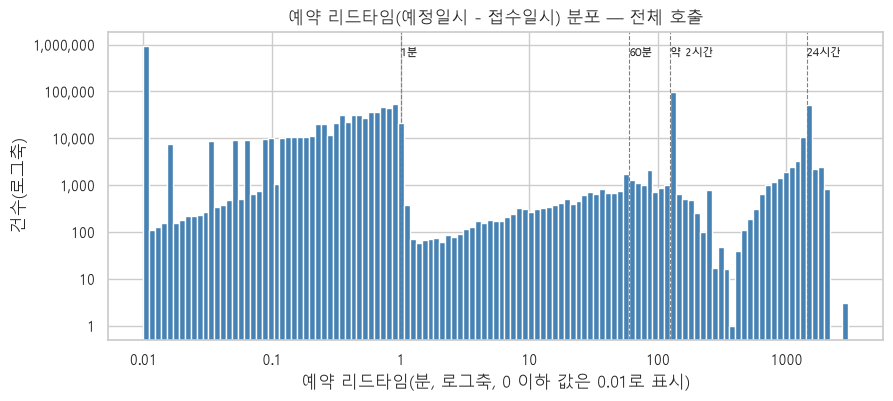

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
x = ana['예약리드_분'].clip(lower=0.01, upper=3000)
ax.hist(x, bins=np.logspace(-2, np.log10(3000), 120), color='steelblue')
ax.set_xscale('log'); ax.set_yscale('log')
for v, lab in [(1, '1분'), (60, '60분'), (125, '약 2시간'), (1440, '24시간')]:
    ax.axvline(v, color='gray', ls='--', lw=0.8); ax.text(v, ax.get_ylim()[1] * 0.3, lab, fontsize=8)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_title('예약 리드타임(예정일시 - 접수일시) 분포 — 전체 호출')
ax.set_xlabel('예약 리드타임(분, 로그축, 0 이하 값은 0.01로 표시)'); ax.set_ylabel('건수(로그축)')
save_fig(fig, 'fig00_reservation_lead_time.png'); plt.show()

**해석 — 호출 유형**
- 즉시호출(|예정−접수| ≤ 1분) 1,523,834건(88.1%), 사전예약(> 60분) 189,278건(10.9%), 분류보류 16,364건(0.9%).
- 사전예약의 리드타임은 약 2시간(120~130분, 99,127건)과 전날(12~24시간, 71,222건) 두 곳에 몰려 있다. 운영 규정과 관련이 있을 수 있으나 데이터만으로는 확인되지 않는다.
- 이용목적이 '예약'으로 시작하는 78,648건 중 78,513건(99.8%)이 사전예약으로 분류되므로, 이 정의는 실제 값과 잘 맞는다. 다만 '예약' 접두어가 없는데 사전예약 리드타임을 가진 건도 110,765건이다. 이용목적만으로는 예약 여부를 판단할 수 없다.
- **시사점**: 사전예약은 접수 시각과 이용 희망 시각 사이에 수 시간이 있다. 따라서 '접수→승차'를 대기시간으로 쓰면 안 되며, 대기시간 분석은 **즉시호출로 한정**한다.

## 5. 대기시간 정의·계산·검증

### 5-1. 사용 가능한 시각과 정의

데이터에 **차량 도착 시각이 없으므로** "호출부터 차량 도착까지"의 엄밀한 대기시간은 계산할 수 없다. 계산 가능한 시간 간격과 의미는 다음과 같다(모두 분 단위).

| 지표 | 계산식 | 의미 | 적용 대상 |
|---|---|---|---|
| **배차대기시간** | 배차일시 − 접수일시 | 호출 접수부터 차량이 배정되기까지 걸린 시간 | 즉시호출 중 배차 기록이 있는 건(완료 + 배차후취소) |
| **탑승소요시간** | 승차일시 − 접수일시 | 호출 접수부터 실제 탑승까지 걸린 시간. 차량 이동·도착 후 탑승 준비 시간이 포함되므로 *도착 대기시간과 같지 않다* | 즉시호출 중 완료 건 |
| 배차후 탑승시간 | 승차일시 − 배차일시 | 차량 배정 후 승차까지(차량 이동 + 탑승 준비) | 즉시호출 중 완료 건 |
| 예정대비 탑승지연 | 승차일시 − 예정일시 | 예약한 시각 대비 실제 탑승 시각의 차이(참고) | 사전예약 중 완료 건 |

- 사전예약 건의 `승차 − 접수`는 예약을 미리 한 기간이 포함되므로 대기시간으로 쓰지 않는다.
- 모든 시각에 날짜가 포함되어 있어 자정을 넘는 호출도 단순 뺄셈으로 정확히 계산된다. 날짜를 보정하지 않는다.
- 배차 전에 취소된 즉시호출은 배차대기시간이 **관측되지 않은 채 중단(우측 절단)** 된 건이다. 따라서 완료 건만으로 계산한 대기시간은 실제 대기 경험을 **과소추정**할 수 있다.

In [9]:
def minutes(a, b):
    return (ana[b] - ana[a]).dt.total_seconds() / 60

ana['배차대기_분'] = minutes('접수일시', '배차일시')
ana['탑승소요_분'] = minutes('접수일시', '승차일시')
ana['배차후탑승_분'] = minutes('배차일시', '승차일시')
ana['예정대비탑승_분'] = minutes('예정일시', '승차일시')
ana['운행시간_분'] = minutes('승차일시', '하차일시')
ana['취소까지_분'] = minutes('접수일시', '취소일시')

imm = ana['호출유형'].eq('즉시호출')
res = ana['호출유형'].eq('사전예약')
done = ana['상태'].eq('완료')
disp_target = imm & ana['상태'].isin(['완료', '배차후취소'])

def validate(name, col, start, end, target, base_mask, base_label):
    v = ana.loc[target, col]
    a_dt = ana.loc[target, start]; b_dt = ana.loc[target, end]
    valid = v.notna() & (v >= 0)
    return {'지표': name, '대상 정의': base_label, '대상 건수': int(target.sum()), '계산 가능(시각 비결측)': int(v.notna().sum()),
            '음수(종료<시작)': int((v < 0).sum()), '0분': int((v == 0).sum()), '180분 초과(이상치 후보)': int((v > 180).sum()),
            '자정 넘김(날짜 다름)': int((a_dt.dt.date != b_dt.dt.date).sum()), '유효(≥0)': int(valid.sum()),
            '유효/대상(%)': round(valid.sum() / target.sum() * 100, 2),
            '유효/전체 즉시호출(%)': round(valid.sum() / imm.sum() * 100, 2),
            '유효/전체 호출(%)': round(valid.sum() / len(ana) * 100, 2)}

wait_valid = pd.DataFrame([
    validate('배차대기시간', '배차대기_분', '접수일시', '배차일시', disp_target, imm, '즉시호출 & (완료|배차후취소)'),
    validate('탑승소요시간', '탑승소요_분', '접수일시', '승차일시', imm & done, imm, '즉시호출 & 완료'),
    validate('배차후 탑승시간', '배차후탑승_분', '배차일시', '승차일시', imm & done, imm, '즉시호출 & 완료'),
    validate('예정대비 탑승지연(참고)', '예정대비탑승_분', '예정일시', '승차일시', res & done, res, '사전예약 & 완료'),
])
save_table(wait_valid, 'table05_wait_validation.csv')
wait_valid.T

,0,1,2,3
지표,배차대기시간,탑승소요시간,배차후 탑승시간,예정대비 탑승지연(참고)
대상 정의,즉시호출 & (완료|배차후취소),즉시호출 & 완료,즉시호출 & 완료,사전예약 & 완료
대상 건수,1380402,1320608,1320608,148897
계산 가능(시각 비결측),1380402,1320608,1320608,148897
음수(종료<시작),1,0,0,4298
0분,0,0,0,0
180분 초과(이상치 후보),390,1180,5,17
자정 넘김(날짜 다름),797,2054,1321,13
유효(≥0),1380401,1320608,1320608,144599
유효/대상(%),100.0,100.0,100.0,97.11


In [10]:
print('배차대기시간 음수 건:')
display(raw.loc[disp_target & (ana['배차대기_분'] < 0), TIME_COLS])
print('즉시호출 탑승소요시간 180분 초과 예시(이상치 후보, 삭제하지 않음):')
display(raw.loc[imm & done & (ana['탑승소요_분'] > 180), TIME_COLS + ['이용목적']].head(5))
ana['배차대기_유효'] = disp_target & ana['배차대기_분'].ge(0)
ana['탑승소요_유효'] = imm & done & ana['탑승소요_분'].ge(0)
ana['탑승소요_이상치후보'] = ana['탑승소요_유효'] & ana['탑승소요_분'].gt(180)

pct = [.05, .1, .25, .5, .75, .9, .95, .99]
wait_stats = pd.concat({
    '배차대기시간(즉시호출, 완료+배차후취소)': ana.loc[ana['배차대기_유효'], '배차대기_분'].describe(percentiles=pct),
    '탑승소요시간(즉시호출, 완료)': ana.loc[ana['탑승소요_유효'], '탑승소요_분'].describe(percentiles=pct),
    '배차후 탑승시간(즉시호출, 완료)': ana.loc[ana['탑승소요_유효'], '배차후탑승_분'].describe(percentiles=pct),
    '취소까지 시간(즉시호출, 배차전취소)': ana.loc[imm & ana['상태'].eq('배차전취소') & ana['취소까지_분'].ge(0), '취소까지_분'].describe(percentiles=pct),
    '예정대비 탑승지연(사전예약, 완료)': ana.loc[res & done, '예정대비탑승_분'].describe(percentiles=pct),
}, axis=1).T.round(2)
save_table(wait_stats.reset_index().rename(columns={'index': '지표'}), 'table06_wait_stats_overall.csv')
wait_stats

배차대기시간 음수 건:


,접수일시,예정일시,배차일시,승차일시,하차일시,취소일시
200,2025-01-01 08:34:51.000,2025-01-01 08:35:00.000,2025-01-01 08:30:00.000,2025-01-01 09:50:00.000,2025-01-01 10:07:00.000,NaN


즉시호출 탑승소요시간 180분 초과 예시(이상치 후보, 삭제하지 않음):


,접수일시,예정일시,배차일시,승차일시,하차일시,취소일시,이용목적
27,2025-01-01 00:39:45.857,2025-01-01 00:40:00.000,2025-01-01 03:39:54.617,2025-01-01 04:14:13.887,2025-01-01 05:01:51.583,NaN,기타
58,2025-01-01 04:44:44.330,2025-01-01 04:45:00.000,2025-01-01 07:47:00.000,2025-01-01 07:58:00.000,2025-01-01 08:54:00.000,NaN,기타
1466,2025-01-02 04:55:36.587,2025-01-02 04:55:36.587,2025-01-02 07:49:09.810,2025-01-02 08:11:16.903,2025-01-02 09:32:02.373,NaN,기타
3613,2025-01-02 11:50:52.060,2025-01-02 11:50:52.060,2025-01-02 11:54:10.157,2025-01-02 15:49:04.420,2025-01-02 15:49:06.873,NaN,기타
10444,2025-01-03 14:27:14.857,2025-01-03 14:27:14.857,2025-01-03 15:00:22.537,2025-01-03 17:34:04.787,2025-01-03 18:13:18.980,NaN,기타


,count,mean,std,min,5%,10%,25%,50%,75%,90%,95%,99%,max
"배차대기시간(즉시호출, 완료+배차후취소)",1380401.0,20.85,23.54,0.17,1.66,2.20,4.73,10.13,29.22,56.46,71.21,99.73,321.18
"탑승소요시간(즉시호출, 완료)",1320608.0,39.26,26.19,0.30,12.48,15.35,21.26,30.84,49.54,77.16,93.93,125.36,341.84
"배차후 탑승시간(즉시호출, 완료)",1320608.0,18.44,8.23,0.05,7.11,9.00,12.61,17.42,23.11,28.97,32.97,42.47,249.39
"취소까지 시간(즉시호출, 배차전취소)",142702.0,17.53,22.59,0.03,0.28,0.40,0.92,7.19,28.11,49.98,63.05,92.71,335.33
"예정대비 탑승지연(사전예약, 완료)",148897.0,27.50,20.81,-1442.29,6.58,11.80,17.93,24.96,33.85,47.28,61.28,93.60,262.25


**판단 — 대기시간 계산 가능 여부: 일부 가능**
- 차량 도착 시각이 없어 '호출→차량 도착' 대기시간은 계산할 수 없다. 대신 즉시호출에서는 **배차대기시간(접수→배차)** 과 **탑승소요시간(접수→승차)** 을 신뢰성 있게 계산할 수 있다.
- 파싱 오류는 0건이다. 음수는 배차대기 1건(접수 08:34:51, 배차 08:30:00)뿐이다. 자정을 넘긴 건(배차대기 797건, 탑승소요 2,054건)도 시각에 날짜가 포함되어 있어 정상 계산되며, 날짜를 보정하지 않았다.
- 유효 관측치는 배차대기 1,380,401건(전체 즉시호출의 90.59%, 전체 호출의 79.82%), 탑승소요 1,320,608건(전체 즉시호출의 86.66%, 전체 호출의 76.36%)이다. 180분 초과 이상치 후보(각각 390건, 1,180건)는 플래그만 표시했고 삭제하지 않았다.
- 즉시호출의 **배차대기시간 중앙값은 10.1분**(평균 20.9분, p90 56.5분), **탑승소요시간 중앙값은 30.8분**(평균 39.3분, p90 77.2분)이다. 배차 후 승차까지 걸린 시간의 중앙값은 17.4분이다. 분포가 오른쪽으로 길게 치우쳐 있으므로 평균보다 중앙값과 p90을 대표값으로 쓴다.
- **선택 편향**: 즉시호출의 9.37%(142,706건)는 배차 전에 취소되었다. 이 건들은 접수 후 중앙값 7.2분(평균 17.5분) 만에 취소되어, 실제로 얼마나 더 기다려야 했는지 관측되지 않는다. 따라서 위 값은 **배차·탑승에 성공한 건**의 대기시간이며, 전체 호출의 대기 경험을 대표하지 않는다(과소추정 가능).
- 사전예약의 '예정대비 탑승지연'(승차−예정)은 중앙값이 25.0분이지만, 4,298건이 음수이고 최소값이 −1,442분이다. 사전예약에서 '예정일시'의 운영상 의미(희망 출발 시각인지 등)가 확인되지 않아 참고용으로만 둔다.

## 6. 데이터 품질 점검

In [11]:
print('완전 중복 행:', int(raw.duplicated().sum()))
key_cols = ['접수일시', '예정일시', '출발동', '목적동']
dup_key = raw.duplicated(subset=key_cols, keep=False)
print('중복 식별자 후보(접수일시+예정일시+출발동+목적동 동일) 행 수:', int(dup_key.sum()))
display(raw.loc[dup_key, key_cols + ['배차일시', '승차일시', '취소일시']].sort_values(key_cols).head(6))

완전 중복 행: 0


중복 식별자 후보(접수일시+예정일시+출발동+목적동 동일) 행 수: 358


,접수일시,예정일시,출발동,목적동,배차일시,승차일시,취소일시
1453,2025-01-02 02:25:00.263,2025-01-02 04:30:00.000,삼성동,신림동,2025-01-02 04:13:16.920,2025-01-02 04:20:05.070,NaN
1455,2025-01-02 02:25:00.263,2025-01-02 04:30:00.000,삼성동,신림동,2025-01-02 04:34:14.457,2025-01-02 04:47:44.920,NaN
12141,2025-01-04 02:25:00.543,2025-01-04 04:30:00.000,삼성동,신림동,2025-01-04 04:05:26.167,2025-01-04 04:40:00.333,NaN
12143,2025-01-04 02:25:00.543,2025-01-04 04:30:00.000,삼성동,신림동,2025-01-04 04:05:54.450,2025-01-04 04:35:04.523,NaN
21922,2025-01-07 02:25:00.923,2025-01-07 04:30:00.000,삼성동,신림동,2025-01-07 04:03:27.410,2025-01-07 05:00:28.850,NaN
21923,2025-01-07 02:25:00.923,2025-01-07 04:30:00.000,삼성동,신림동,2025-01-07 04:14:30.177,2025-01-07 04:38:24.853,NaN


In [12]:
anom = [
    ('완전 중복 행', int(raw.duplicated().sum())),
    ('배차일시 < 접수일시', int((ana['배차대기_분'] < 0).sum())),
    ('취소일시 < 접수일시', int((ana['취소까지_분'] < 0).sum())),
    ('취소일시가 2025년 이전(예: 2024-01-01 09:00)', int((ana['취소일시'] < '2025-01-01').sum())),
    ('예정일시가 접수일시보다 1분 넘게 앞섬', int((ana['예약리드_분'] < -1).sum())),
    ('하차는 있으나 승차 없음', int((~has['승차일시'] & has['하차일시']).sum())),
    ('승차는 있으나 하차 없음', int((has['승차일시'] & ~has['하차일시']).sum())),
    ('배차·승차·하차·취소 모두 없음', int((~has['배차일시'] & ~has['승차일시'] & ~has['하차일시'] & ~has['취소일시']).sum())),
    ('하차와 취소가 모두 기록됨', int((has['하차일시'] & has['취소일시']).sum())),
    ('즉시호출 완료 건 탑승소요 180분 초과', int(ana['탑승소요_이상치후보'].sum())),
    ('운행시간(하차−승차) 180분 초과', int((ana['운행시간_분'] > 180).sum())),
    ('완료 건 요금 = 0', int((done & ana['요금'].eq(0)).sum())),
    ('완료 건 승차거리 = 0', int((done & ana['승차거리'].eq(0)).sum())),
    ('요금 > 50,000', int((ana['요금'] > 50000).sum())),
    ('승차거리 > 100,000(단위 미확인)', int((ana['승차거리'] > 100000).sum())),
    ('접수일시가 2024년(전년도 사전예약)', int((ana['접수일시'] < '2025-01-01').sum())),
]
anom_tbl = pd.DataFrame(anom, columns=['점검 규칙', '건수'])
anom_tbl['전체 대비(%)'] = (anom_tbl['건수'] / len(ana) * 100).round(4)
save_table(anom_tbl, 'table07_anomaly_candidates.csv')
anom_tbl

,점검 규칙,건수,전체 대비(%)
0,완전 중복 행,0,0.0000
1,배차일시 < 접수일시,1,0.0001
2,취소일시 < 접수일시,6,0.0003
3,취소일시가 2025년 이전(예: 2024-01-01 09:00),15,0.0009
4,예정일시가 접수일시보다 1분 넘게 앞섬,126,0.0073
5,하차는 있으나 승차 없음,691,0.0400
6,승차는 있으나 하차 없음,94,0.0054
7,배차·승차·하차·취소 모두 없음,24,0.0014
8,하차와 취소가 모두 기록됨,2,0.0001
9,즉시호출 완료 건 탑승소요 180분 초과,1180,0.0682


In [13]:
num_stats = ana.loc[:, ['요금', '승차거리']].describe(percentiles=[.01, .25, .5, .75, .99, .999]).T.round(1)
num_stats_done = ana.loc[done, ['요금', '승차거리', '운행시간_분']].describe(percentiles=[.01, .25, .5, .75, .99, .999]).T.round(1)
print('전체 행 기준'); display(num_stats)
print('완료 건 기준'); display(num_stats_done)

전체 행 기준


,count,mean,std,min,1%,25%,50%,75%,99%,99.9%,max
요금,1484016.0,2282.6,4055.9,0.0,1500.0,1500.0,1700.0,2900.0,5000.0,7700.0,805180.0
승차거리,1729476.0,7304.7,9363.6,0.0,0.0,2080.0,4520.0,9475.0,38329.0,64728.3,809463.0


완료 건 기준


,count,mean,std,min,1%,25%,50%,75%,99%,99.9%,max
요금,1483322.0,2281.5,3837.9,0.0,1500.0,1500.0,1700.0,2900.0,5000.0,7700.0,805180.0
승차거리,1483322.0,8514.6,9496.9,0.0,619.0,3059.0,5446.0,10729.0,39562.6,67332.4,809463.0
운행시간_분,1483322.0,26.1,19.2,0.0,3.7,12.8,20.7,34.2,89.1,128.2,1465.0


In [14]:
ana['예정일'] = ana['예정일시'].dt.normalize()
print('연도별 행 수(접수일시 기준):'); display(ana['접수일시'].dt.year.value_counts().sort_index())
print('연도별 행 수(예정일시 기준):'); display(ana['예정일시'].dt.year.value_counts().sort_index())
all_days = pd.date_range('2025-01-01', '2025-12-31', freq='D')
daily = ana.groupby('예정일').size().reindex(all_days)
print('2025년 중 호출 기록이 없는 날짜 수(예정일시 기준):', int(daily.isna().sum()))
print('일별 호출 건수 요약:'); display(daily.describe().round(1))
low_days = daily.sort_values().head(10).rename('호출 건수').to_frame()
low_days['요일'] = [WD[d.weekday()] for d in low_days.index]
print('호출이 가장 적은 10일:'); display(low_days)

연도별 행 수(접수일시 기준):


접수일시
2024         61
2025    1729415
Name: count, dtype: int64

연도별 행 수(예정일시 기준):


예정일시
2025    1729476
Name: count, dtype: int64

2025년 중 호출 기록이 없는 날짜 수(예정일시 기준): 0
일별 호출 건수 요약:


count     365.0
mean     4738.3
std      1781.4
min      1429.0
25%      2469.0
50%      5830.0
75%      6090.0
max      6757.0
dtype: float64

호출이 가장 적은 10일:


,호출 건수,요일
2025-01-30,1429,목
2025-01-01,1437,수
2025-01-28,1486,화
2025-01-29,1676,수
2025-10-07,1700,화
2025-01-05,1844,일
2025-10-06,1882,월
2025-02-09,1902,일
2025-04-13,1903,일
2025-01-19,1924,일


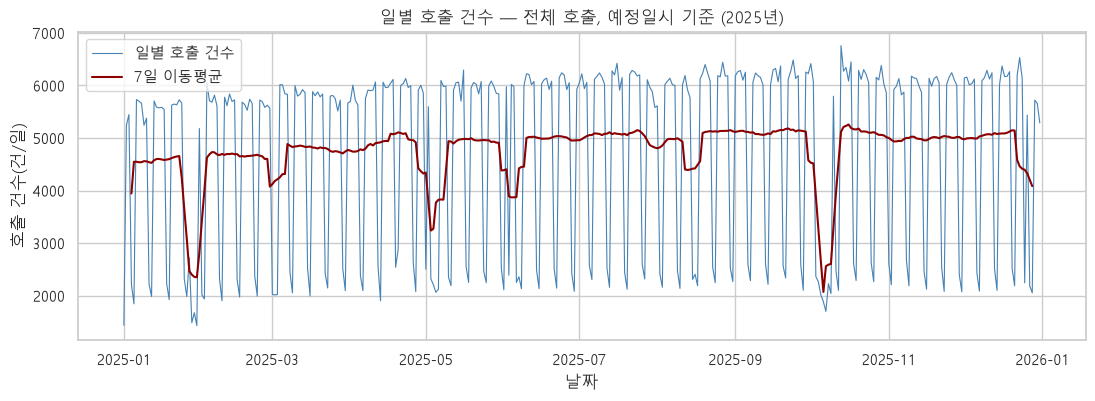

In [15]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.values, lw=0.8, color='steelblue', label='일별 호출 건수')
ax.plot(daily.index, daily.rolling(7, center=True).mean(), color='darkred', lw=1.5, label='7일 이동평균')
ax.set_title('일별 호출 건수 — 전체 호출, 예정일시 기준 (2025년)')
ax.set_xlabel('날짜'); ax.set_ylabel('호출 건수(건/일)'); ax.legend()
save_fig(fig, 'fig01_daily_calls.png'); plt.show()

**해석 — 데이터 품질**
- 완전 중복 행은 0건이다. 호출 ID가 없어 건 단위 중복을 확정할 수는 없다. 접수일시·예정일시·출발동·목적동이 모두 같은 358행은 같은 시각 패턴으로 반복 접수된 예약(예: 02:25 접수, 04:30 예정)이다. 이 행들은 배차·승차 시각이 서로 달라, 같은 예약으로 차량 여러 대가 운행된 것으로 보인다. 중복으로 제거하지 않는다.
- 시각 불일치(하차는 있으나 승차 없음 691건 등), 2024-01-01 09:00 같은 비정상 취소일시 15건, 요금 50,000원 초과 98건, 승차거리 100,000 초과 96건은 각각 전체의 0.05% 미만이다. 핵심 분석에 미치는 영향은 작지만 `table07`에 기록했다. 완료 건 중 승차거리 0인 건은 6,254건(0.36%)이다(승차거리 단위 미확인).
- 관측 기간은 이용 예정 기준 **2025-01-01 ~ 2025-12-31(365일 모두 존재)** 이다. 접수일시가 2024-12-31인 61건은 모두 2025-01-01 이용 사전예약이다. **2024년 이용 데이터는 없다.**
- 일별 호출은 평균 4,738건이고 평일·주말에 따라 두 층으로 나뉜다(중앙값 5,830건, 하위 25% 2,469건). 호출이 가장 적은 날(1/28~1/30, 1/1, 10/6~10/7, 일요일들)은 설·추석 연휴 등 공휴일과 겹친다. 공휴일 정보는 데이터에 없으므로 외부에서 확보해야 하며, 예측 모델의 필수 변수다.

## 7. EDA A — 시간대별 이용 패턴

집계 기준을 다음처럼 구분한다.
- **호출 수요**: 전체 호출(취소 포함), `예정일시`(이용 희망 시각) 기준. 즉시호출은 예정 ≈ 접수이므로 접수 시각과 사실상 같다.
- **즉시호출 접수**: 즉시호출만, `접수일시` 기준.
- **탑승**: 완료 건, `승차일시` 기준.

모든 일평균은 2025년 365일(요일별은 해당 요일 수)로 나눈 값이다.

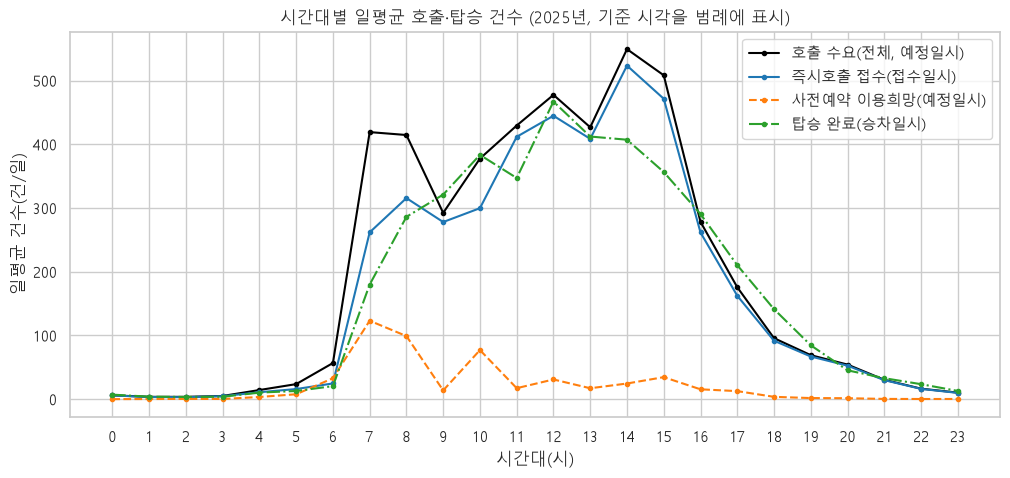

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
"호출 수요(전체, 예정일시)",6.1,3.7,3.7,5.0,14.4,23.6,56.7,419.1,414.6,292.3,377.6,429.4,477.5,426.7,549.3,508.3,278.3,175.7,95.7,69.1,54.3,30.4,16.5,10.3
즉시호출 접수(접수일시),5.9,3.3,3.2,4.7,10.9,15.9,24.7,261.8,315.5,278.0,299.7,411.8,444.8,408.6,523.5,471.5,261.6,162.3,91.7,67.0,52.6,29.9,16.2,9.8
사전예약 이용희망(예정일시),0.1,0.3,0.4,0.3,3.5,7.7,32.8,123.1,99.0,13.8,77.0,17.3,30.9,17.2,24.6,34.6,15.5,12.7,3.7,1.8,1.5,0.4,0.3,0.3
탑승 완료(승차일시),7.1,3.9,3.5,3.8,10.3,12.9,20.5,179.9,286.1,321.0,383.4,347.1,467.0,412.2,407.2,356.5,290.5,210.3,141.3,84.5,45.3,32.9,23.5,12.9


In [16]:
ana['예정시'] = ana['예정일시'].dt.hour
ana['예정요일'] = ana['예정일시'].dt.weekday
ana['접수시'] = ana['접수일시'].dt.hour
ana['접수요일'] = ana['접수일시'].dt.weekday
ana['접수일'] = ana['접수일시'].dt.normalize()
n_days = 365
in25_s = ana['예정일시'].dt.year.eq(2025)
in25_r = ana['접수일시'].dt.year.eq(2025)
in25_b = ana['승차일시'].dt.year.eq(2025)

hourly = pd.DataFrame({
    '호출 수요(전체, 예정일시)': ana.loc[in25_s].groupby('예정시').size() / n_days,
    '즉시호출 접수(접수일시)': ana.loc[in25_r & imm].groupby('접수시').size() / n_days,
    '사전예약 이용희망(예정일시)': ana.loc[in25_s & res].groupby('예정시').size() / n_days,
    '탑승 완료(승차일시)': ana.loc[in25_b & done].groupby(ana['승차일시'].dt.hour).size() / n_days,
}).reindex(range(24)).fillna(0)

fig, ax = plt.subplots(figsize=(12, 5))
styles = {'호출 수요(전체, 예정일시)': ('black', '-'), '즉시호출 접수(접수일시)': ('tab:blue', '-'),
          '사전예약 이용희망(예정일시)': ('tab:orange', '--'), '탑승 완료(승차일시)': ('tab:green', '-.')}
for c, (col, ls) in styles.items():
    ax.plot(hourly.index, hourly[c], marker='o', ms=3, color=col, ls=ls, label=c)
ax.set_xticks(range(24)); ax.set_xlabel('시간대(시)'); ax.set_ylabel('일평균 건수(건/일)')
ax.set_title('시간대별 일평균 호출·탑승 건수 (2025년, 기준 시각을 범례에 표시)')
ax.legend()
save_fig(fig, 'fig02_hourly_calls_boardings.png'); plt.show()
hourly.round(1).T

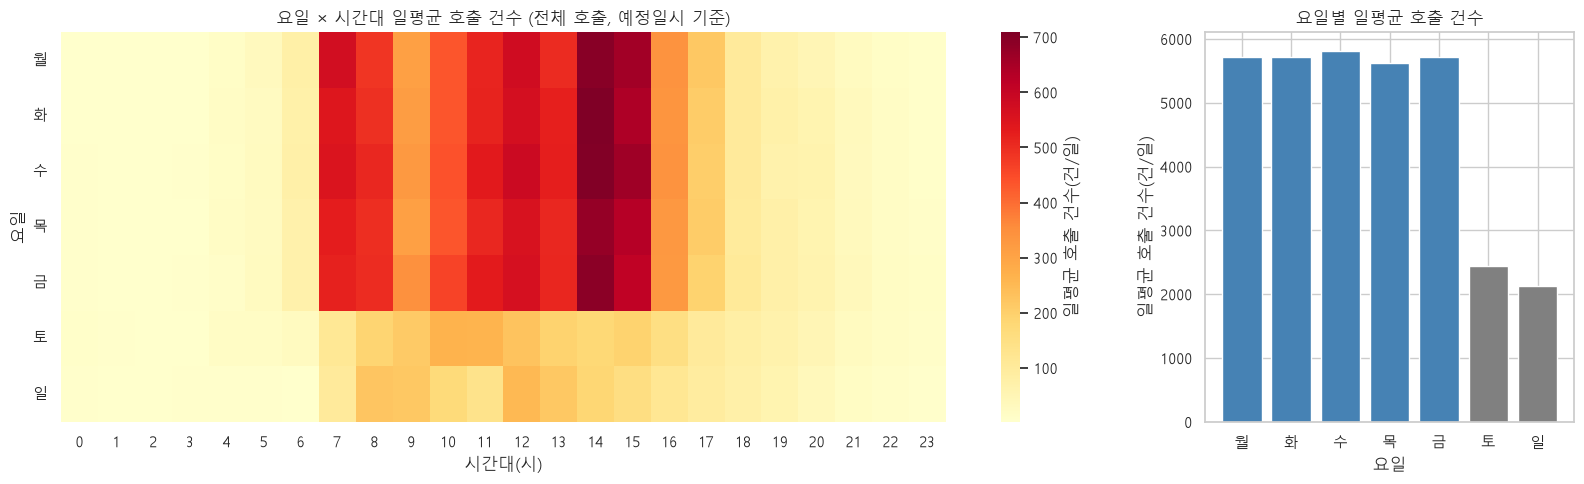

,요일,해당 요일 수,일평균 호출,즉시호출 배차전취소율(%)
0,월,52,5716.7,7.87
1,화,52,5717.3,8.47
2,수,53,5811.8,8.93
3,목,52,5615.1,8.77
4,금,52,5709.3,9.84
5,토,52,2444.9,12.96
6,일,52,2132.3,12.79


In [17]:
days_per_wd = pd.Series(all_days.weekday).value_counts().sort_index()
wd_hour = ana.loc[in25_s].groupby(['예정요일', '예정시']).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
wd_hour = wd_hour.div(days_per_wd, axis=0)
wd_hour.index = WD

wd_daily = ana.loc[in25_s].groupby('예정요일').size() / days_per_wd
wd_cancel = ana.loc[in25_s & imm].groupby('예정요일')['상태'].apply(lambda s: s.eq('배차전취소').mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [3, 1]})
sns.heatmap(wd_hour, cmap='YlOrRd', ax=axes[0], cbar_kws={'label': '일평균 호출 건수(건/일)'}, annot=False)
axes[0].set_title('요일 × 시간대 일평균 호출 건수 (전체 호출, 예정일시 기준)')
axes[0].set_xlabel('시간대(시)'); axes[0].set_ylabel('요일'); axes[0].tick_params(axis='y', rotation=0)
axes[1].bar(WD, wd_daily.values, color=['steelblue'] * 5 + ['gray'] * 2)
axes[1].set_title('요일별 일평균 호출 건수'); axes[1].set_xlabel('요일'); axes[1].set_ylabel('일평균 호출 건수(건/일)')
plt.tight_layout(); save_fig(fig, 'fig03_weekday_hour_heatmap_calls.png'); plt.show()
weekday_tbl = pd.DataFrame({'요일': WD, '해당 요일 수': days_per_wd.values, '일평균 호출': wd_daily.values.round(1),
                            '즉시호출 배차전취소율(%)': wd_cancel.values.round(2)})
weekday_tbl

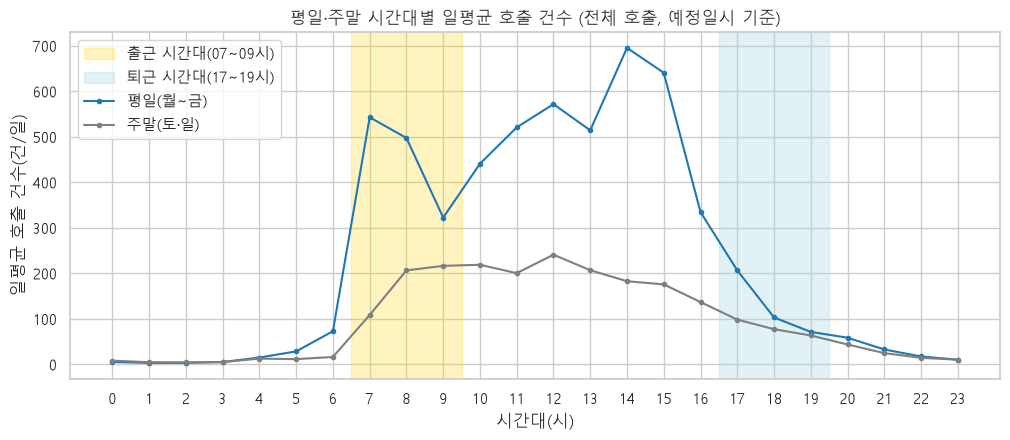

,구간,시간대,평일(월~금) 일평균 호출,주말(토·일) 일평균 호출,평일 비중(%)
0,출근(07~09시),"[7, 8, 9]",1362.9,531.4,23.9
1,퇴근(17~19시),"[17, 18, 19]",380.9,239.1,6.7
2,주간(10~16시),"[10, 11, 12, 13, 14, 15, 16]",3718.5,1362.4,65.1
3,야간(20~06시),"[20, 21, 22, 23, 0, 1, 2, 3, 4, 5, 6]",252.1,155.7,4.4


In [18]:
is_wkend = ana['예정요일'] >= 5
n_wkday = int((all_days.weekday < 5).sum()); n_wkend = int((all_days.weekday >= 5).sum())
prof = pd.DataFrame({
    '평일(월~금)': ana.loc[in25_s & ~is_wkend].groupby('예정시').size() / n_wkday,
    '주말(토·일)': ana.loc[in25_s & is_wkend].groupby('예정시').size() / n_wkend,
}).reindex(range(24)).fillna(0)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.axvspan(6.5, 9.5, color='gold', alpha=0.25, label='출근 시간대(07~09시)')
ax.axvspan(16.5, 19.5, color='lightblue', alpha=0.35, label='퇴근 시간대(17~19시)')
for c, col in zip(prof.columns, ['tab:blue', 'tab:gray']):
    ax.plot(prof.index, prof[c], marker='o', ms=3, color=col, label=c)
ax.set_xticks(range(24)); ax.set_xlabel('시간대(시)'); ax.set_ylabel('일평균 호출 건수(건/일)')
ax.set_title('평일·주말 시간대별 일평균 호출 건수 (전체 호출, 예정일시 기준)'); ax.legend()
save_fig(fig, 'fig04_weekday_weekend_hourly.png'); plt.show()
commute = pd.DataFrame({
    '구간': ['출근(07~09시)', '퇴근(17~19시)', '주간(10~16시)', '야간(20~06시)'],
    '시간대': [[7, 8, 9], [17, 18, 19], list(range(10, 17)), [20, 21, 22, 23, 0, 1, 2, 3, 4, 5, 6]]})
for c in prof.columns:
    commute[c + ' 일평균 호출'] = [prof.loc[h, c].sum().round(1) for h in commute['시간대']]
commute['평일 비중(%)'] = (commute['평일(월~금) 일평균 호출'] / prof['평일(월~금)'].sum() * 100).round(1)
commute['시간대'] = commute['시간대'].astype(str)
commute

In [19]:
ana['예정월'] = ana['예정일시'].dt.month
dim = pd.Series(all_days.month).value_counts().sort_index()
g = ana.loc[in25_s]
monthly = pd.DataFrame({
    '호출(전체)': g.groupby('예정월').size(),
    '즉시호출': g.loc[imm].groupby('예정월').size(),
    '사전예약': g.loc[res].groupby('예정월').size(),
    '완료': g.loc[done].groupby('예정월').size(),
})
monthly['일수'] = dim
monthly['일평균 호출'] = (monthly['호출(전체)'] / monthly['일수']).round(1)
monthly['즉시호출 배차전취소율(%)'] = (g.loc[imm].groupby('예정월')['상태'].apply(lambda s: s.eq('배차전취소').mean()) * 100).round(2)
monthly['즉시호출 배차대기 중앙값(분)'] = g.loc[g['배차대기_유효']].groupby('예정월')['배차대기_분'].median().round(1)
monthly['즉시호출 탑승소요 중앙값(분)'] = g.loc[g['탑승소요_유효']].groupby('예정월')['탑승소요_분'].median().round(1)
monthly['즉시호출 탑승소요 평균(분)'] = g.loc[g['탑승소요_유효']].groupby('예정월')['탑승소요_분'].mean().round(1)
monthly['완료 중 임차택시 비중(%)'] = (g.loc[done].groupby('예정월')['차량구분'].apply(lambda s: s.astype(str).eq('임차택시').mean()) * 100).round(2)
monthly.index.name = '월'
save_table(monthly.reset_index(), 'table08_monthly_summary.csv')
monthly

,호출(전체),즉시호출,사전예약,완료,일수,일평균 호출,즉시호출 배차전취소율(%),즉시호출 배차대기 중앙값(분),즉시호출 탑승소요 중앙값(분),즉시호출 탑승소요 평균(분),완료 중 임차택시 비중(%)
월,,,,,,,,,,,
1,125319,110855,13288,109000,31,4042.5,7.74,8.9,27.9,33.8,18.81
2,130751,115723,13839,113881,28,4669.7,8.20,9.5,29.8,37.8,19.73
3,140781,123764,15530,121381,31,4541.3,8.99,10.0,30.6,40.6,18.98
4,149673,131160,16894,127107,30,4989.1,10.07,12.5,33.1,42.0,18.57
5,141168,123936,15681,119897,31,4553.8,10.13,11.8,32.6,40.7,19.20
6,140268,123335,15659,121439,30,4675.6,8.36,9.4,28.8,35.7,22.67
7,159627,140963,17312,138924,31,5149.3,8.09,9.3,28.5,34.8,22.00
8,147637,131054,15478,128121,31,4762.5,8.61,9.5,29.1,35.8,22.26
9,155737,137301,17125,132173,30,5191.2,10.74,12.4,33.0,42.6,22.40


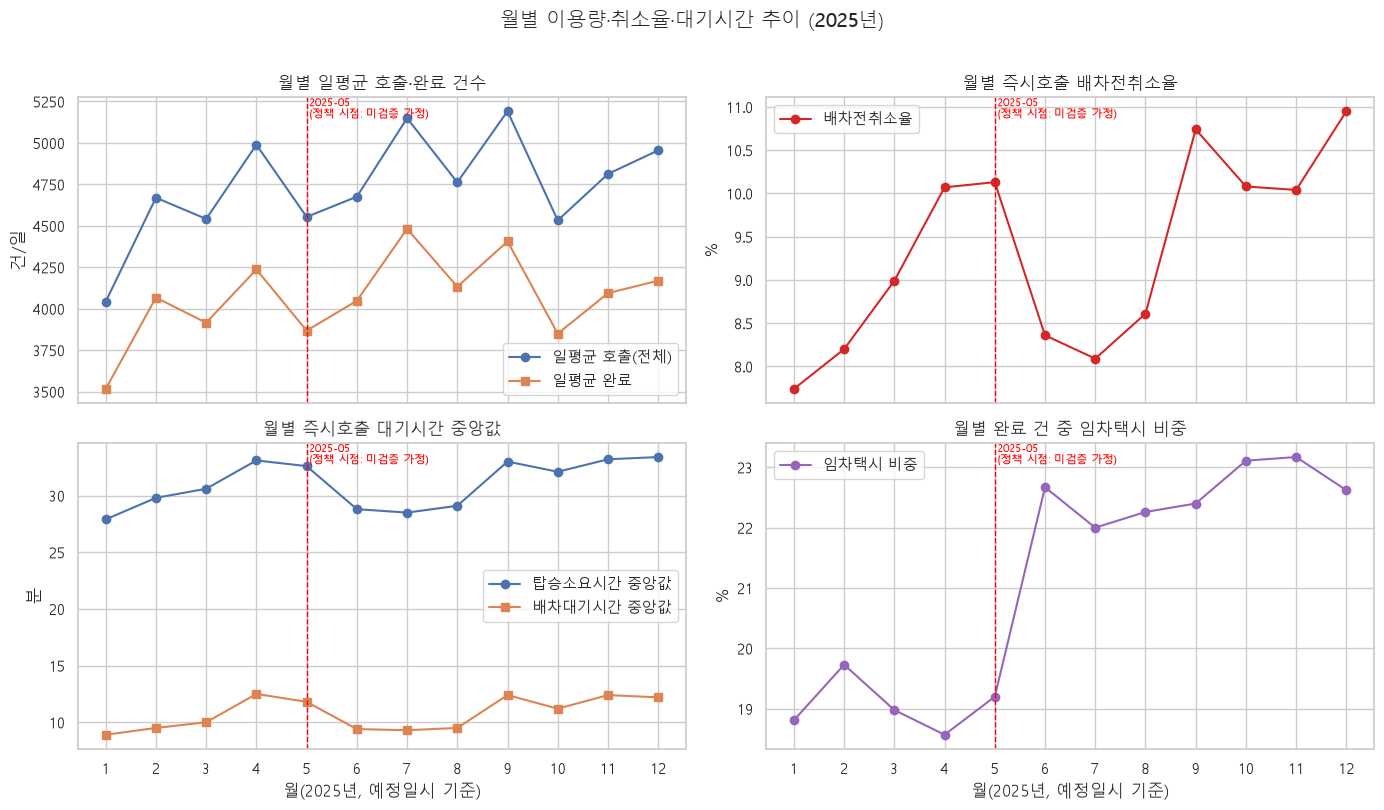

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
m = monthly.index
def mark_may(ax):
    ax.axvline(5, color='red', ls='--', lw=1)
    ax.text(5.05, ax.get_ylim()[1], '2025-05\n(정책 시점: 미검증 가정)', color='red', va='top', fontsize=8)
axes[0, 0].plot(m, monthly['일평균 호출'], marker='o', label='일평균 호출(전체)')
axes[0, 0].plot(m, monthly['완료'] / monthly['일수'], marker='s', label='일평균 완료')
axes[0, 0].set_ylabel('건/일'); axes[0, 0].set_title('월별 일평균 호출·완료 건수'); axes[0, 0].legend(); mark_may(axes[0, 0])
axes[0, 1].plot(m, monthly['즉시호출 배차전취소율(%)'], marker='o', color='tab:red', label='배차전취소율')
axes[0, 1].set_ylabel('%'); axes[0, 1].set_title('월별 즉시호출 배차전취소율'); axes[0, 1].legend(); mark_may(axes[0, 1])
axes[1, 0].plot(m, monthly['즉시호출 탑승소요 중앙값(분)'], marker='o', label='탑승소요시간 중앙값')
axes[1, 0].plot(m, monthly['즉시호출 배차대기 중앙값(분)'], marker='s', label='배차대기시간 중앙값')
axes[1, 0].set_ylabel('분'); axes[1, 0].set_title('월별 즉시호출 대기시간 중앙값'); axes[1, 0].legend(); mark_may(axes[1, 0])
axes[1, 1].plot(m, monthly['완료 중 임차택시 비중(%)'], marker='o', color='tab:purple', label='임차택시 비중')
axes[1, 1].set_ylabel('%'); axes[1, 1].set_title('월별 완료 건 중 임차택시 비중'); axes[1, 1].legend(); mark_may(axes[1, 1])
for ax in axes[1]:
    ax.set_xticks(range(1, 13)); ax.set_xlabel('월(2025년, 예정일시 기준)')
fig.suptitle('월별 이용량·취소율·대기시간 추이 (2025년)', y=1.01)
plt.tight_layout(); save_fig(fig, 'fig05_monthly_trends.png'); plt.show()

**해석 — 시간대별 이용 패턴**
- 호출(전체, 예정일시 기준)은 07~16시에 집중된다. 시간대별 일평균은 14시 549건으로 가장 많고, 15시 508건, 12시 478건, 11시 429건, 07시 419건 순이다. 00~05시는 시간당 25건 미만이다.
- 07~08시 호출(일평균 약 415~419건)에는 사전예약 이용 희망분(07시 123건, 08시 99건)이 크게 포함되어 있다. 아침 첫 시간대는 예약 수요가 집중되는 구간이다.
- 탑승 완료(승차일시 기준) 곡선은 호출보다 늦은 시간 쪽으로 밀려 있다. 07시 호출은 419건인데 07시 탑승은 180건이고, 16~18시에는 탑승이 호출보다 많다. **어느 시각을 기준으로 집계하느냐에 따라 '혼잡 시간'이 달라지므로**, 예측 대상의 기준 시각을 명확히 정해야 한다.
- 평일 일평균 호출은 5,615~5,812건이고, 주말은 토 2,445건, 일 2,132건으로 평일의 약 40%다. 그런데 즉시호출 배차전취소율은 주말(토 12.96%, 일 12.79%)이 평일(7.87~9.84%)보다 높다.
- 평일 하루 호출 중 출근 시간대(07~09시)가 23.9%, 주간(10~16시)이 65.1%를 차지한다. 퇴근 시간대(17~19시)는 6.7%에 그쳐, 일반 대중교통과 같은 퇴근 피크는 뚜렷하지 않다.
- 월별 일평균 호출은 4,043건(1월)에서 5,191건(9월) 사이다. 월별 배차전취소율(7.7~11.0%)과 배차대기 중앙값(8.9~12.5분)은 4~5월과 9~12월에 높다.

## 8. EDA B — 대기시간 분포 (즉시호출)

5절에서 검증한 **즉시호출**의 배차대기시간(접수→배차)과 탑승소요시간(접수→승차)을 사용한다. 시간대·요일은 **접수일시** 기준이다. 대기시간은 완료(탑승소요) 또는 배차된 건(배차대기)에서만 관측되므로 *전체 호출의 대기시간으로 일반화하지 않는다*.

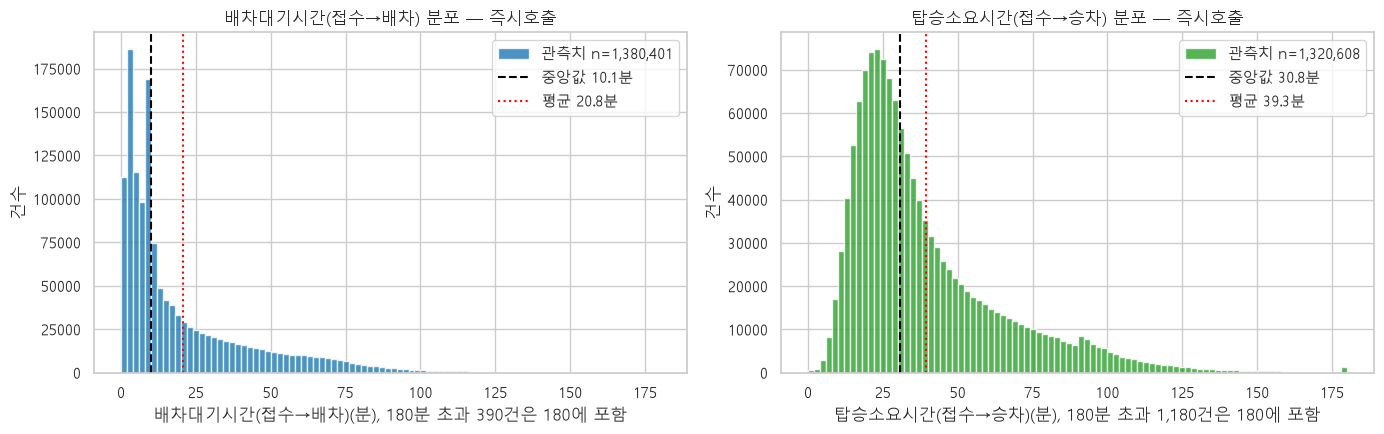

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, flag, title, color in [
        (axes[0], '배차대기_분', '배차대기_유효', '배차대기시간(접수→배차)', 'tab:blue'),
        (axes[1], '탑승소요_분', '탑승소요_유효', '탑승소요시간(접수→승차)', 'tab:green')]:
    v = ana.loc[ana[flag], col]
    over = int((v > 180).sum())
    ax.hist(v.clip(upper=180), bins=90, range=(0, 180), color=color, alpha=0.8, label=f'관측치 n={len(v):,}')
    ax.axvline(v.median(), color='black', ls='--', label=f'중앙값 {v.median():.1f}분')
    ax.axvline(v.mean(), color='red', ls=':', label=f'평균 {v.mean():.1f}분')
    ax.set_title(f'{title} 분포 — 즉시호출'); ax.set_xlabel(f'{title}(분), 180분 초과 {over:,}건은 180에 포함')
    ax.set_ylabel('건수'); ax.legend()
plt.tight_layout(); save_fig(fig, 'fig06_wait_distribution.png'); plt.show()

In [22]:
def q(p):
    f = lambda s: s.quantile(p); f.__name__ = f'p{int(p*100)}'; return f

w = ana.loc[ana['배차대기_유효'], ['접수시', '접수요일', '배차대기_분']]
b = ana.loc[ana['탑승소요_유효'], ['접수시', '접수요일', '탑승소요_분']]
imm_calls = ana.loc[imm]
hour_tbl = pd.DataFrame({
    '즉시호출 건수': imm_calls.groupby('접수시').size(),
    '배차전취소율(%)': imm_calls.groupby('접수시')['상태'].apply(lambda s: s.eq('배차전취소').mean() * 100),
    '배차대기 n': w.groupby('접수시').size(),
    '배차대기 평균': w.groupby('접수시')['배차대기_분'].mean(),
    '배차대기 중앙값': w.groupby('접수시')['배차대기_분'].median(),
    '배차대기 p90': w.groupby('접수시')['배차대기_분'].quantile(.9),
    '탑승소요 n': b.groupby('접수시').size(),
    '탑승소요 평균': b.groupby('접수시')['탑승소요_분'].mean(),
    '탑승소요 중앙값': b.groupby('접수시')['탑승소요_분'].median(),
    '탑승소요 p25': b.groupby('접수시')['탑승소요_분'].quantile(.25),
    '탑승소요 p75': b.groupby('접수시')['탑승소요_분'].quantile(.75),
    '탑승소요 p90': b.groupby('접수시')['탑승소요_분'].quantile(.9),
    '탑승소요 60분 이상 비율(%)': b.groupby('접수시')['탑승소요_분'].apply(lambda s: (s >= 60).mean() * 100),
}).round(2)
hour_tbl.index.name = '접수 시간대(시)'
save_table(hour_tbl.reset_index(), 'table09_hourly_wait_summary.csv')
hour_tbl

,즉시호출 건수,배차전취소율(%),배차대기 n,배차대기 평균,배차대기 중앙값,배차대기 p90,탑승소요 n,탑승소요 평균,탑승소요 중앙값,탑승소요 p25,탑승소요 p75,탑승소요 p90,탑승소요 60분 이상 비율(%)
접수 시간대(시),,,,,,,,,,,,,
0,2156,17.90,1767,19.68,12.16,47.31,1660,44.27,39.47,28.35,54.40,74.69,19.70
1,1217,17.42,1005,18.18,10.39,42.61,932,42.12,37.42,26.94,50.51,70.57,16.52
2,1163,7.82,1071,9.91,8.49,18.20,1012,30.48,28.24,21.66,37.35,46.72,2.57
3,1724,3.36,1666,7.84,7.42,11.90,1622,29.11,27.74,21.37,34.96,43.13,1.54
4,3986,7.53,3686,13.82,8.53,32.91,3560,34.67,30.24,22.79,41.10,56.03,8.26
5,5803,11.20,5150,30.38,16.92,76.64,4803,51.66,41.28,25.25,75.08,99.23,35.54
6,9017,7.94,8297,31.83,29.95,61.76,7852,52.24,50.66,35.53,66.12,81.98,33.33
7,95552,11.98,84063,36.10,33.55,71.25,79516,57.07,54.27,35.59,76.44,93.44,42.73
8,115175,11.29,102137,36.54,34.95,70.14,97450,56.31,54.59,35.27,74.72,91.47,42.79


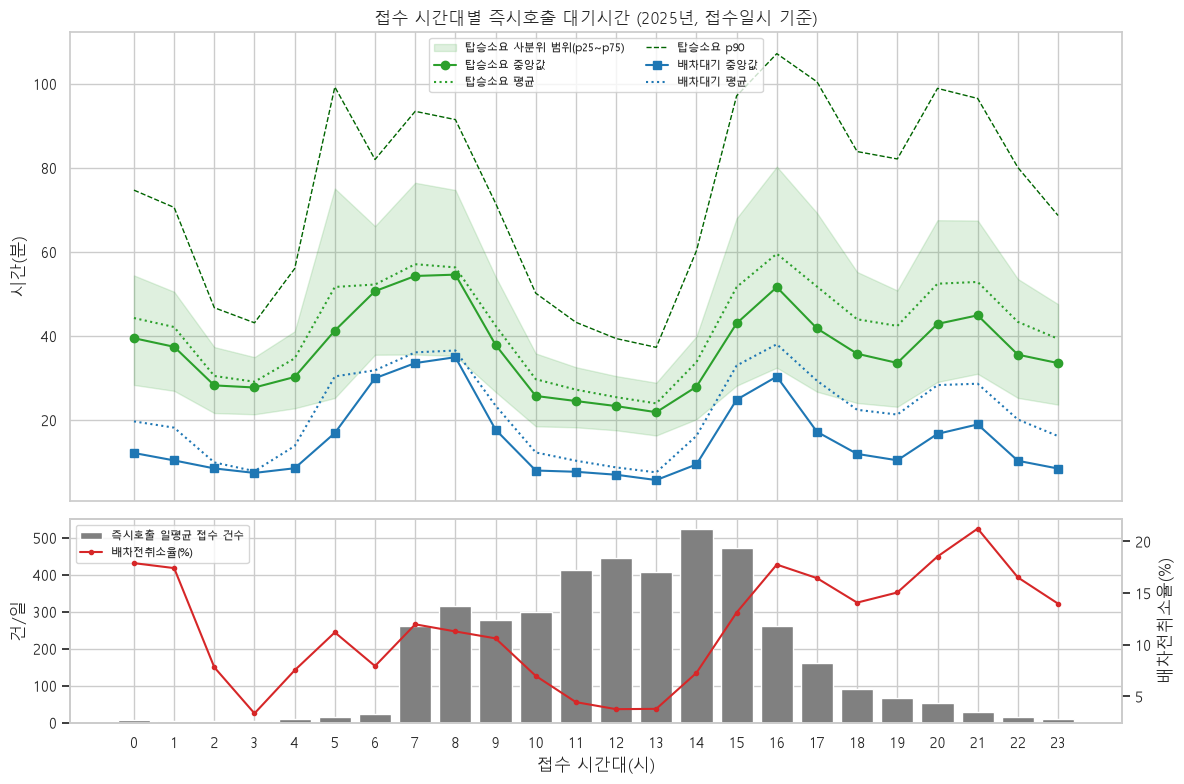

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
ax = axes[0]
h = hour_tbl.index
ax.fill_between(h, hour_tbl['탑승소요 p25'], hour_tbl['탑승소요 p75'], color='tab:green', alpha=0.15, label='탑승소요 사분위 범위(p25~p75)')
ax.plot(h, hour_tbl['탑승소요 중앙값'], marker='o', color='tab:green', label='탑승소요 중앙값')
ax.plot(h, hour_tbl['탑승소요 평균'], ls=':', color='tab:green', label='탑승소요 평균')
ax.plot(h, hour_tbl['탑승소요 p90'], ls='--', color='darkgreen', lw=1, label='탑승소요 p90')
ax.plot(h, hour_tbl['배차대기 중앙값'], marker='s', color='tab:blue', label='배차대기 중앙값')
ax.plot(h, hour_tbl['배차대기 평균'], ls=':', color='tab:blue', label='배차대기 평균')
ax.set_ylabel('시간(분)'); ax.set_title('접수 시간대별 즉시호출 대기시간 (2025년, 접수일시 기준)'); ax.legend(ncol=2, fontsize=8)
axes[1].bar(h, hour_tbl['즉시호출 건수'] / 365, color='gray', label='즉시호출 일평균 접수 건수')
ax2 = axes[1].twinx(); ax2.plot(h, hour_tbl['배차전취소율(%)'], color='tab:red', marker='o', ms=3, label='배차전취소율(%)')
axes[1].set_ylabel('건/일'); ax2.set_ylabel('배차전취소율(%)'); ax2.grid(False)
axes[1].set_xlabel('접수 시간대(시)'); axes[1].set_xticks(range(24))
l1, lb1 = axes[1].get_legend_handles_labels(); l2, lb2 = ax2.get_legend_handles_labels(); axes[1].legend(l1 + l2, lb1 + lb2, fontsize=8, loc='upper left')
plt.tight_layout(); save_fig(fig, 'fig07_wait_by_hour.png'); plt.show()

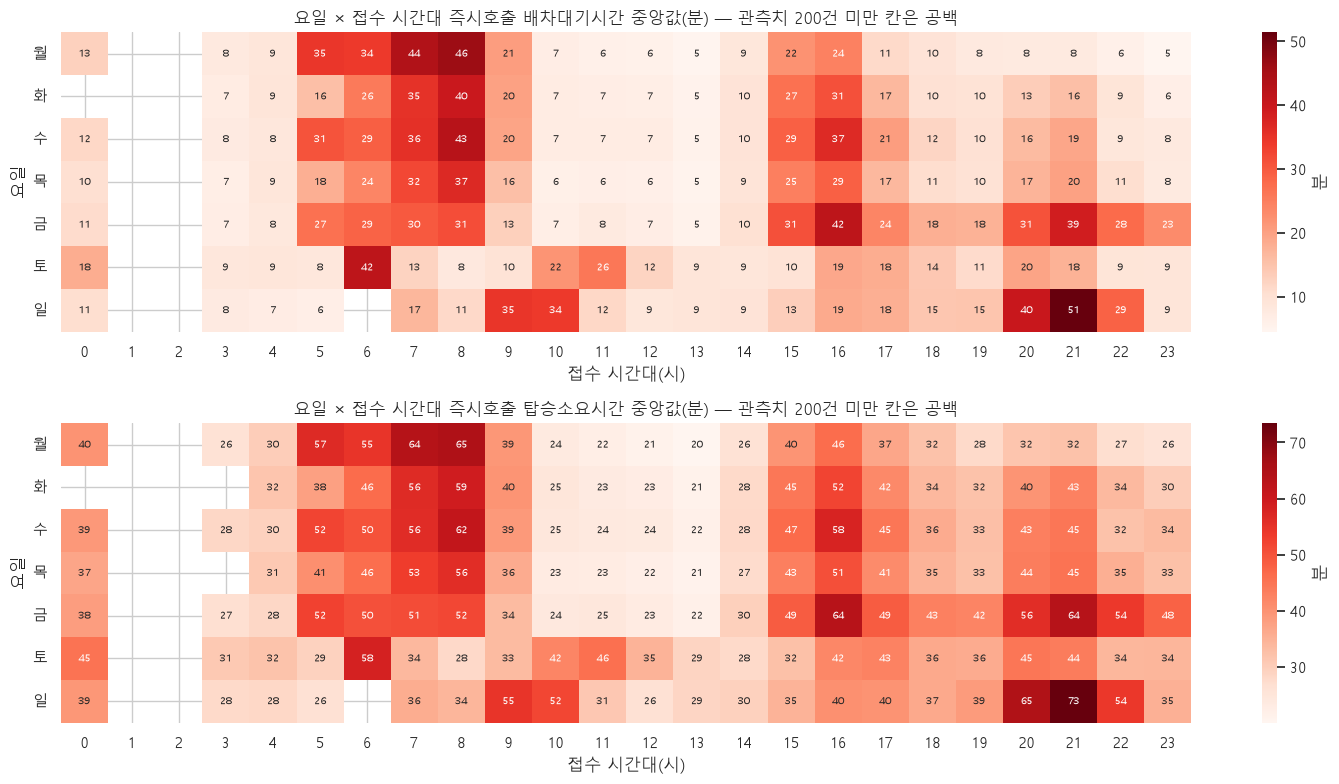

,요일,배차대기 평균,배차대기 중앙값,탑승소요 평균,탑승소요 중앙값,탑승소요 60분 이상 비율(%)
0,월,19.37,9.48,37.17,28.87,16.83
1,화,20.45,10.08,38.67,30.50,17.40
2,수,21.84,10.54,40.09,31.06,19.06
3,목,19.65,9.75,37.84,29.61,16.71
4,금,21.69,10.39,40.13,31.01,18.29
5,토,21.86,12.03,42.25,35.16,18.86
6,일,22.89,12.38,42.19,34.20,19.45


In [24]:
MIN_N = 200
def heat(df, col):
    piv_m = df.groupby(['접수요일', '접수시'])[col].median().unstack().reindex(columns=range(24))
    piv_n = df.groupby(['접수요일', '접수시'])[col].size().unstack().reindex(columns=range(24)).fillna(0)
    piv_m.index = WD; piv_n.index = WD
    return piv_m, piv_n
hw, nw = heat(w, '배차대기_분'); hb, nb = heat(b, '탑승소요_분')
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
for ax, piv, n, title in [(axes[0], hw, nw, '배차대기시간 중앙값(분)'), (axes[1], hb, nb, '탑승소요시간 중앙값(분)')]:
    sns.heatmap(piv, mask=n < MIN_N, cmap='Reds', annot=True, fmt='.0f', annot_kws={'size': 7}, ax=ax, cbar_kws={'label': '분'})
    ax.set_title(f'요일 × 접수 시간대 즉시호출 {title} — 관측치 {MIN_N}건 미만 칸은 공백')
    ax.set_xlabel('접수 시간대(시)'); ax.set_ylabel('요일'); ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); save_fig(fig, 'fig08_weekday_hour_heatmap_wait.png'); plt.show()
wd_wait = pd.DataFrame({
    '요일': WD,
    '배차대기 평균': w.groupby('접수요일')['배차대기_분'].mean().values, '배차대기 중앙값': w.groupby('접수요일')['배차대기_분'].median().values,
    '탑승소요 평균': b.groupby('접수요일')['탑승소요_분'].mean().values, '탑승소요 중앙값': b.groupby('접수요일')['탑승소요_분'].median().values,
    '탑승소요 60분 이상 비율(%)': b.groupby('접수요일')['탑승소요_분'].apply(lambda s: (s >= 60).mean() * 100).values,
}).round(2)
save_table(wd_wait, 'table10_weekday_wait_summary.csv')
wd_wait

### 장시간 대기(탑승소요 60분 이상)가 관측된 건의 특징

In [25]:
bb = ana.loc[ana['탑승소요_유효'], ['접수시', '접수요일', '출발구', '차량구분', '장애유형', '탑승소요_분']].copy()
bb['장시간'] = bb['탑승소요_분'] >= 60
print(f"즉시호출 완료 건 중 탑승소요 60분 이상: {bb['장시간'].sum():,}건 ({bb['장시간'].mean()*100:.2f}%)")
top_hours = hour_tbl['탑승소요 60분 이상 비율(%)'].sort_values(ascending=False).head(6)
print('장시간 대기 비율이 높은 접수 시간대:'); display(top_hours)
gu = bb.groupby('출발구', observed=True).agg(건수=('장시간', 'size'), 장시간비율=('장시간', 'mean'), 탑승소요중앙값=('탑승소요_분', 'median'))
gu = gu[gu['건수'] >= 5000].sort_values('장시간비율', ascending=False)
gu['장시간비율'] = (gu['장시간비율'] * 100).round(2)
print('출발구별(완료 5,000건 이상) 장시간 대기 비율 상·하위 5개:'); display(pd.concat([gu.head(5), gu.tail(5)]))
veh = bb.groupby('차량구분', observed=True).agg(건수=('장시간', 'size'), 장시간비율=('장시간', 'mean'), 탑승소요중앙값=('탑승소요_분', 'median'))
veh['장시간비율'] = (veh['장시간비율'] * 100).round(2)
print('차량구분별(배차된 차량 종류):'); display(veh)
save_table(gu.reset_index(), 'table11_long_wait_by_district.csv')

즉시호출 완료 건 중 탑승소요 60분 이상: 235,993건 (17.87%)
장시간 대기 비율이 높은 접수 시간대:


접수 시간대(시)
8     42.79
7     42.73
16    41.55
5     35.54
6     33.33
21    31.63
Name: 탑승소요 60분 이상 비율(%), dtype: float64

출발구별(완료 5,000건 이상) 장시간 대기 비율 상·하위 5개:


,건수,장시간비율,탑승소요중앙값
출발구,,,
서초구,35637,31.72,43.439550
중구,22320,28.36,40.123117
금천구,20967,26.10,36.647667
종로구,40943,25.01,35.486000
관악구,45143,24.60,35.883450
강동구,81111,14.49,27.760717
강북구,40480,13.33,28.937608
중랑구,54928,12.50,26.565133
도봉구,45146,10.38,26.435108


차량구분별(배차된 차량 종류):


,건수,장시간비율,탑승소요중앙값
차량구분,,,
임차택시,282760,13.11,26.792250
특장차,1037848,19.17,31.961975


**해석 — 대기시간 분포와 혼잡 시간대(즉시호출, 접수일시 기준)**
- 혼잡 구간이 하루 두 번 뚜렷하게 나타난다.
  - **아침(07~08시 접수)**: 배차대기 중앙값 33.6~35.0분, 탑승소요 중앙값 54.3~54.6분, 탑승소요 60분 이상 비율 약 43%.
  - **오후(15~16시 접수)**: 16시 기준 배차대기 중앙값 30.3분, 탑승소요 중앙값 51.6분, 60분 이상 41.6%, 배차전취소율 17.8%.
- 호출이 가장 많은 11~13시는 오히려 대기가 가장 짧다(배차대기 중앙값 5.7~7.7분, 탑승소요 중앙값 21.9~24.5분, 배차전취소율 3.8~4.5%). **호출이 많은 시간대와 대기가 긴 시간대가 일치하지 않는다.** 대기시간은 수요 자체보다 그 시간대의 공급(가동 차량·운전원) 대비 수요에 좌우될 가능성이 높으며, 이를 검증하려면 공급 자료가 필요하다.
- 야간(20~21시 접수)은 호출이 적은데도 배차대기 중앙값이 16.7~19.0분이고, 배차전취소율은 18.5~21.2%로 하루 중 가장 높다. 공급이 적은 시간대일 가능성이 있으나 미검증이다.
- 요일 × 시간대 히트맵에서는 평일 07~08시와 15~16시가 반복적으로 높다. 금요일 16시(배차대기 중앙값 42분)·21시(39분)와 일요일 21시(51분)가 특히 높다. 주말은 오전 피크가 약하지만, 하루 전체 탑승소요 중앙값은 평일보다 길다(토 35.2분, 일 34.2분, 월 28.9분).
- 즉시호출 완료 건 중 탑승소요가 60분 이상인 건은 235,993건(17.87%)이다. 출발구별 60분 이상 비율은 노원구 8.8%에서 서초구 31.7%까지 차이가 크다. 다만 출발구는 시간대·이용자 구성과 얽혀 있어 지역 효과로 단정하지 않는다.
- 임차택시가 배차된 건의 탑승소요 중앙값(26.8분)은 특장차(32.0분)보다 짧다. 차량 유형이 이용자 특성(휠체어 이용 여부 등)과 연결될 수 있으므로, 두 집단을 직접 비교할 수 없다.

## 9. EDA C — 이용량과 대기시간의 관계

**분석 단위**: 날짜 × 접수 시간대(1시간) 칸. 
- **이용량**: 해당 칸에 접수된 즉시호출 건수(취소 포함)
- **대기시간**: 해당 칸 즉시호출의 배차대기시간 중앙값(배차된 건)
- 관측치가 적은 칸의 노이즈를 줄이기 위해 배차된 건이 20건 이상인 칸만 사용한다.

시간대 자체(운행 인력 교대, 예약 집중 등)가 두 변수에 동시에 영향을 줄 수 있으므로, 같은 시간대 안에서의 상관도 따로 확인한다. 상관은 인과를 의미하지 않는다.

In [26]:
cell_calls = imm_calls.groupby(['접수일', '접수시']).size().rename('즉시호출건수')
cell_cancel = imm_calls.groupby(['접수일', '접수시'])['상태'].apply(lambda s: s.eq('배차전취소').mean() * 100).rename('배차전취소율')
wd_ = ana.loc[ana['배차대기_유효']]
cell_wait = wd_.groupby(['접수일', '접수시'])['배차대기_분'].agg(['median', 'size']).rename(columns={'median': '배차대기중앙값', 'size': '배차n'})
cell = pd.concat([cell_calls, cell_cancel, cell_wait], axis=1).reset_index()
cell = cell[(cell['배차n'] >= 20) & cell['접수일'].dt.year.eq(2025)]
print('분석 칸 수:', len(cell))
pear = stats.pearsonr(cell['즉시호출건수'], cell['배차대기중앙값'])
spear = stats.spearmanr(cell['즉시호출건수'], cell['배차대기중앙값'])
print(f'Pearson r = {pear.statistic:.3f} (p={pear.pvalue:.2g}), Spearman ρ = {spear.statistic:.3f} (p={spear.pvalue:.2g})')
within = cell.groupby('접수시').apply(lambda d: pd.Series({'칸 수': len(d), 'Spearman ρ': stats.spearmanr(d['즉시호출건수'], d['배차대기중앙값']).statistic if len(d) >= 30 else np.nan}))
print('같은 접수 시간대 안에서의 Spearman 상관(칸 30개 이상):'); display(within.round(3).T)
cell['이용량 10분위'] = pd.qcut(cell['즉시호출건수'], 10, duplicates='drop')
dec = cell.groupby('이용량 10분위', observed=True).agg(칸수=('배차대기중앙값', 'size'), 배차대기중앙값의중앙값=('배차대기중앙값', 'median'),
                                                    배차대기중앙값의평균=('배차대기중앙값', 'mean'), 배차전취소율평균=('배차전취소율', 'mean')).round(2)
display(dec)
corr_tbl = pd.DataFrame([{'분석 단위': '날짜×접수시간대(배차 20건 이상)', '칸 수': len(cell), 'Pearson r': round(pear.statistic, 3), 'Spearman rho': round(spear.statistic, 3),
                          '시간대 내 Spearman 중앙값': round(within['Spearman ρ'].median(), 3)}])
save_table(corr_tbl, 'table12_volume_wait_correlation.csv')
save_table(dec.reset_index().astype({'이용량 10분위': str}), 'table13_volume_decile_wait.csv')

분석 칸 수: 5671
Pearson r = -0.130 (p=6.8e-23), Spearman ρ = -0.184 (p=2.1e-44)
같은 접수 시간대 안에서의 Spearman 상관(칸 30개 이상):


접수시,0,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
칸 수,1.0,45.000,235.000,362.000,365.000,365.000,365.000,365.00,365.000,365.000,365.000,365.000,365.000,365.000,365.000,365.000,353.00,260.00,33.000,2.0
Spearman ρ,NaN,0.025,0.601,0.734,0.379,-0.194,-0.681,-0.37,-0.294,-0.428,0.444,0.482,0.251,-0.187,-0.055,0.292,0.12,0.35,0.328,NaN


,칸수,배차대기중앙값의중앙값,배차대기중앙값의평균,배차전취소율평균
이용량 10분위,,,,
"(19.999, 40.0]",582,19.64,23.46,11.64
"(40.0, 66.0]",569,14.35,23.22,15.32
"(66.0, 95.0]",553,14.22,20.37,15.32
"(95.0, 156.0]",565,11.14,19.08,13.68
"(156.0, 207.0]",577,12.14,18.85,12.67
"(207.0, 296.0]",565,17.03,22.03,12.27
"(296.0, 364.0]",559,24.59,27.24,11.89
"(364.0, 485.0]",570,21.03,24.58,8.47
"(485.0, 570.0]",564,5.69,8.30,3.82


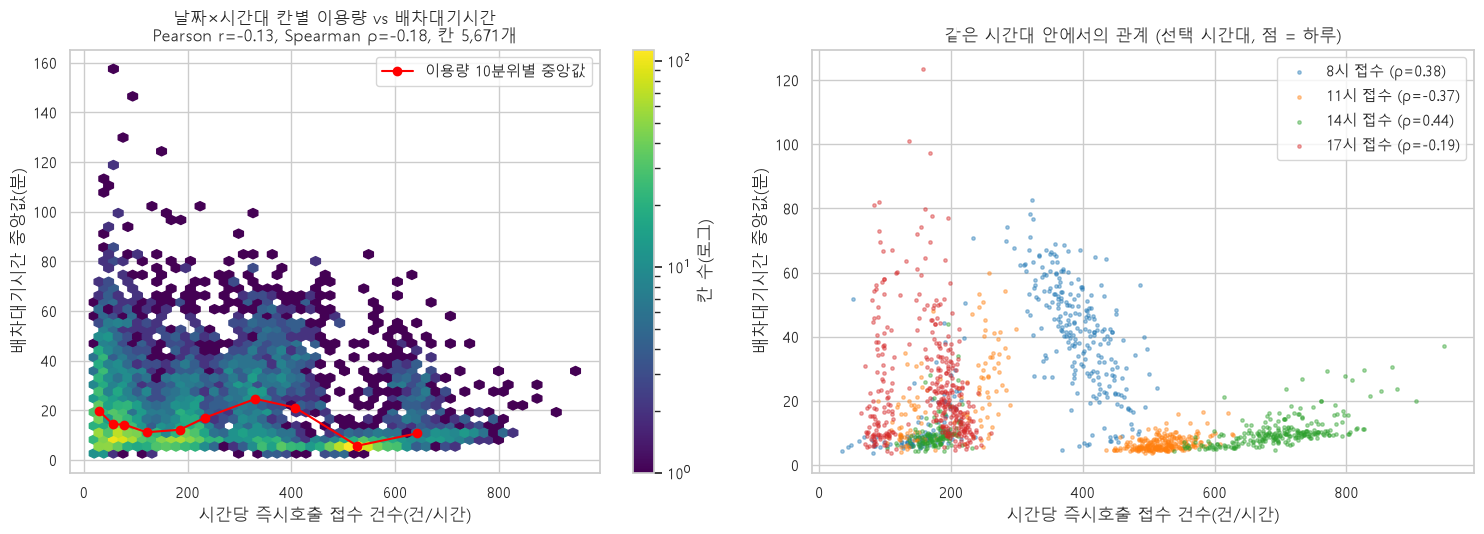

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
hb_ = axes[0].hexbin(cell['즉시호출건수'], cell['배차대기중앙값'], gridsize=50, cmap='viridis', mincnt=1, bins='log')
fig.colorbar(hb_, ax=axes[0], label='칸 수(로그)')
mid = cell.groupby('이용량 10분위', observed=True).agg(x=('즉시호출건수', 'median'), y=('배차대기중앙값', 'median'))
axes[0].plot(mid['x'], mid['y'], color='red', marker='o', label='이용량 10분위별 중앙값')
axes[0].set_xlabel('시간당 즉시호출 접수 건수(건/시간)'); axes[0].set_ylabel('배차대기시간 중앙값(분)')
axes[0].set_title(f'날짜×시간대 칸별 이용량 vs 배차대기시간\nPearson r={pear.statistic:.2f}, Spearman ρ={spear.statistic:.2f}, 칸 {len(cell):,}개')
axes[0].legend()
sel = [8, 11, 14, 17]
for hh, col in zip(sel, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']):
    d = cell[cell['접수시'] == hh]
    axes[1].scatter(d['즉시호출건수'], d['배차대기중앙값'], s=6, alpha=0.4, color=col, label=f'{hh}시 접수 (ρ={within.loc[hh, "Spearman ρ"]:.2f})')
axes[1].set_xlabel('시간당 즉시호출 접수 건수(건/시간)'); axes[1].set_ylabel('배차대기시간 중앙값(분)')
axes[1].set_title('같은 시간대 안에서의 관계 (선택 시간대, 점 = 하루)'); axes[1].legend()
plt.tight_layout(); save_fig(fig, 'fig09_volume_vs_wait.png'); plt.show()

**해석 — 이용량과 대기시간의 관계(날짜 × 접수시간대 5,671칸)**
- 전체 상관은 약한 음의 관계다(Pearson r = −0.13, Spearman ρ = −0.18). 이용량 10분위별로 보면 단조적이지 않다. 중간 구간(시간당 296~364건)의 배차대기 중앙값이 24.6분으로 가장 길고, 최상위 구간(485건 이상)은 5.7~10.7분으로 짧다. **비선형 관계이며, 시간대가 두 변수에 동시에 영향을 주는 교란 구조다.** 점심 시간대는 호출이 많아도 대기가 짧고, 아침·오후 피크는 호출이 그보다 적어도 대기가 길다.
- 같은 시간대 안에서 날짜 간 변동을 보면 방향이 시간대마다 다르다. 06~08시(ρ = 0.60, 0.73, 0.38)와 14~15시(ρ = 0.44, 0.48)는 양의 관계로, 호출이 많은 날일수록 대기가 길다. 10~13시는 음의 관계다(ρ = −0.29 ~ −0.68). 음의 관계는 '호출이 적고 대기가 긴 주말'과 '호출이 많고 대기가 짧은 평일'이 섞인 결과일 수 있다(요일 교란, 미검증).
- 이 결과는 **상관일 뿐 인과가 아니다.** 공급량 자료 없이는 '수요가 공급 여력에 가까워질 때 대기가 늘어난다'는 메커니즘을 확인할 수 없다.
- **시사점**: 대기시간 예측에는 시간대·요일과 해당 시간의 수요를 함께 넣어야 한다. '호출 많음 = 혼잡'으로 정의하면 혼잡 시간대를 잘못 판단하게 된다.

## 10. EDA D — 2025년 5월 전후 비교 가능성 (보조 질문)

- 정책 시행일, 적용 시간대, 증차 시점 등은 이 데이터에 포함되어 있지 않으며 **검증되지 않은 정보**다. 아래에서 2025-05는 *가정한 기준점*으로만 표시한다.
- 데이터에 2024년이 없으므로 **전년 동기 비교는 불가능**하다. 2025년 내 1~4월과 6~12월 비교만 가능하며, 이 차이에는 계절성·공휴일·수요 변화가 섞여 있다.

In [28]:
print('예정일시 기준 관측 범위:', ana['예정일시'].min(), '~', ana['예정일시'].max())
print('접수일시 기준 2024년 행:', int((ana['접수일시'].dt.year == 2024).sum()), '건(모두 2025-01-01 이용 예정 사전예약 여부 확인 →',
      ana.loc[ana['접수일시'].dt.year == 2024, '호출유형'].value_counts().to_dict(), ')')
period = np.select([ana['예정월'].between(1, 4), ana['예정월'].eq(5), ana['예정월'].between(6, 12)], ['1~4월', '5월', '6~12월'], '')
pp = ana.assign(기간=period).loc[in25_s]
pp_tbl = pd.DataFrame({
    '일수': pd.Series({'1~4월': 120, '5월': 31, '6~12월': 214}),
    '일평균 호출': pp.groupby('기간').size() / pd.Series({'1~4월': 120, '5월': 31, '6~12월': 214}),
    '즉시호출 배차전취소율(%)': pp.loc[imm].groupby('기간')['상태'].apply(lambda s: s.eq('배차전취소').mean() * 100),
    '배차대기 중앙값(분)': pp.loc[pp['배차대기_유효']].groupby('기간')['배차대기_분'].median(),
    '탑승소요 중앙값(분)': pp.loc[pp['탑승소요_유효']].groupby('기간')['탑승소요_분'].median(),
    '완료 중 임차택시 비중(%)': pp.loc[done].groupby('기간')['차량구분'].apply(lambda s: s.astype(str).eq('임차택시').mean() * 100),
}).round(2)
pp_tbl

예정일시 기준 관측 범위: 2025-01-01 00:01:26.127000 ~ 2025-12-31 23:59:00
접수일시 기준 2024년 행: 61 건(모두 2025-01-01 이용 예정 사전예약 여부 확인 → {'사전예약': 61} )


,일수,일평균 호출,즉시호출 배차전취소율(%),배차대기 중앙값(분),탑승소요 중앙값(분),완료 중 임차택시 비중(%)
1~4월,120,4554.37,8.81,9.79,30.27,19.01
5월,31,4553.81,10.13,11.85,32.55,19.20
6~12월,214,4868.15,9.55,10.21,30.91,22.59


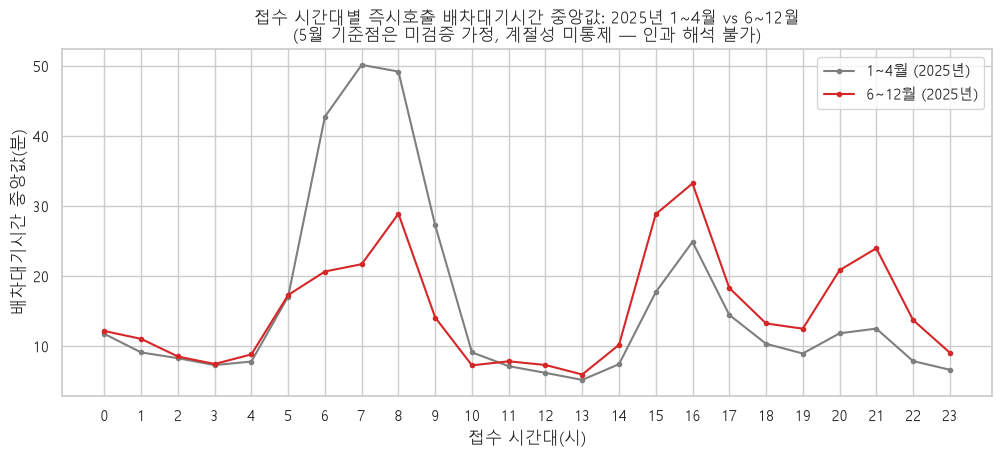

In [29]:
pre = ana['배차대기_유효'] & ana['예정월'].between(1, 4)
post = ana['배차대기_유효'] & ana['예정월'].between(6, 12)
cmp = pd.DataFrame({'1~4월': ana.loc[pre].groupby('접수시')['배차대기_분'].median(),
                    '6~12월': ana.loc[post].groupby('접수시')['배차대기_분'].median()}).reindex(range(24))
fig, ax = plt.subplots(figsize=(12, 4.5))
for c, col in zip(cmp.columns, ['tab:gray', 'tab:red']):
    ax.plot(cmp.index, cmp[c], marker='o', ms=3, color=col, label=f'{c} (2025년)')
ax.set_xticks(range(24)); ax.set_xlabel('접수 시간대(시)'); ax.set_ylabel('배차대기시간 중앙값(분)')
ax.set_title('접수 시간대별 즉시호출 배차대기시간 중앙값: 2025년 1~4월 vs 6~12월\n(5월 기준점은 미검증 가정, 계절성 미통제 — 인과 해석 불가)')
ax.legend(); save_fig(fig, 'fig10_pre_post_may_hourly_wait.png'); plt.show()

**해석 — 2025년 5월 전후 비교: 현재는 후속 과제로 남김**
- 데이터 범위는 2025-01-01 ~ 2025-12-31(이용 예정 기준)이다. 5월 전 4개월(120일)과 후 7개월(214일)이 모두 있어 시간대별 추이를 시각화할 수는 있다.
- 1~4월 대비 6~12월의 배차대기 중앙값은 9.8분 → 10.2분, 탑승소요 중앙값은 30.3분 → 30.9분, 배차전취소율은 8.8% → 9.6%로, 개선 신호가 보이지 않는다. 같은 기간 일평균 호출은 4,554건 → 4,868건으로 늘었다.
- 데이터에서 직접 확인되는 변화는 **완료 건 중 임차택시 비중이 5월 19.2%에서 6월 22.7%로 계단식으로 상승**하고, 이후 22~23%를 유지했다는 점이다. 공급 구성이 바뀌었을 수 있으나, 그 원인(정책, 계약 변경 등)은 확인되지 않았다.
- 2024년 데이터가 없어 전년 동기 비교가 불가능하다. 따라서 계절성(예: 9~12월의 대기 증가)과 정책 효과를 분리할 수 없다. 정책 시행일, 적용 시간대, 증차 시점도 검증되지 않았다.
- **결론**: 정책 전후 비교는 보조 질문으로 두고, 2024년 탑승내역과 정책 문서를 확보한 뒤 수행한다. 현재 결과를 정책 효과로 해석하지 않는다.

## 11. 차고지 데이터 활용 가능성

In [30]:
garage = pd.read_csv(GARAGE_FILE, encoding='utf-8-sig')
print('행 수:', garage.shape[0], '| 열 수:', garage.shape[1])
display(garage.dtypes.rename('자료형').to_frame().T)
display(garage.head(10))
print('결측:', garage.isna().sum().to_dict())
print('차고지명 중복:', int(garage['차고지명'].duplicated().sum()))
display(garage['시설명'].value_counts().rename('차고지 수').to_frame())
display(garage.groupby('구분')['주차대수'].agg(['count', 'sum', 'mean']).round(1))
print('주차대수 합계:', int(garage['주차대수'].sum()))

행 수: 44 | 열 수: 5


,시설명,구분,차고지명,주차대수,상세주소
자료형,str,str,str,int64,str


,시설명,구분,차고지명,주차대수,상세주소
0,민간,동부,가든파이브,10,송파구 충민로 66
1,민간,서부,가산디지털,12,금천구 가산디지털1로 225
2,서울시설공단,서부,개화산주차장,15,강서구 방화동 845
3,서울시설공단,서부,고척차고지,10,구로구 고척로45길 39
4,서울시설공단,서부,구파발환승,10,은평구 진관동 66-30
5,민간,서부,남부여성발전센터,12,금천구 시흥동 산139-2
6,서울시설공단,서부,대림운동장,10,영등포구 대림3동 780
7,서울시설공단,동부,도봉산차고지,20,도봉구 도봉동 341-1
8,서울시설공단,동부,동대문구청,10,동대문구 용두동 39-90
9,서울시설공단,서부,동작주차공원,10,동작구 동작동 326


결측: {'시설명': 0, '구분': 0, '차고지명': 0, '주차대수': 0, '상세주소': 0}
차고지명 중복: 0


,차고지 수
시설명,
서울시설공단,34
민간,10


,count,sum,mean
구분,,,
동부,21,348,16.6
서부,23,343,14.9


주차대수 합계: 691


In [31]:
print('탑승내역 컬럼:', list(raw.columns))
print('차고지 컬럼  :', list(garage.columns))
print('공통 컬럼명  :', set(raw.columns) & set(garage.columns))
garage['자치구'] = garage['상세주소'].str.split().str[0]
print('차고지 주소에서 추출한 자치구:', garage['자치구'].nunique(), '개 —', sorted(garage['자치구'].unique()))

탑승내역 컬럼: ['접수일시', '예정일시', '배차일시', '승차일시', '하차일시', '취소일시', '출발구', '출발동', '목적구', '목적동', '이용목적', '요금', '승차거리', '차량구분', '장애유형']
차고지 컬럼  : ['시설명', '구분', '차고지명', '주차대수', '상세주소']
공통 컬럼명  : set()
차고지 주소에서 추출한 자치구: 24 개 — ['강남구', '강동구', '강북구', '강서구', '관악구', '광진구', '구로구', '금천구', '노원구', '도봉구', '동대문구', '동작구', '마포구', '서초구', '성동구', '성북구', '송파구', '양천구', '영등포구', '용산구', '은평구', '종로구', '중구', '중랑구']


**연결 가능성 판단**
- 탑승내역에는 차량번호, 차고지명, 소속(동부/서부) 등 **차고지와 연결할 식별자가 없다**. 따라서 개별 운행 건 단위의 병합은 **불가능**하다.
- 유일한 공통 요소는 '자치구' 이름(차고지 `상세주소`의 첫 단어 ↔ 탑승내역 `출발구`)이다. 이는 지역 단위의 **참고용 대조**일 뿐, 어떤 차량이 어느 차고지에서 출발했는지를 뜻하지 않는다.
- 차고지 파일 기준일(2026-07-14)과 탑승내역 기간(2025년)도 다르다. 2025년 당시 차고지 구성과 같다는 보장이 없다.
- 아래 표는 구 단위 집계 후의 1:1 대조이며, 병합 키 중복과 행 수 변화를 함께 확인한다.

In [32]:
g_gu = garage.groupby('자치구').agg(차고지수=('차고지명', 'size'), 주차대수합=('주차대수', 'sum')).reset_index()
c_gu = (ana.loc[in25_s].groupby('출발구', observed=True).size().rename('출발 호출 건수').reset_index()
        .rename(columns={'출발구': '자치구'}))
seoul_gu = c_gu.sort_values('출발 호출 건수', ascending=False).head(25)
print('호출 출발구 상위 25개가 모두 "구"로 끝나는가:', seoul_gu['자치구'].str.endswith('구').all())
print('병합 전 — 차고지 구별 집계 행:', len(g_gu), '(키 중복', int(g_gu['자치구'].duplicated().sum()), ') | 서울 출발구 행:', len(seoul_gu),
      '(키 중복', int(seoul_gu['자치구'].duplicated().sum()), ')')
gu_cmp = seoul_gu.merge(g_gu, on='자치구', how='left', validate='one_to_one')
print('병합 후 행 수:', len(gu_cmp), '| 차고지 없는 구:', gu_cmp.loc[gu_cmp['차고지수'].isna(), '자치구'].tolist())
print('차고지 구 중 서울 출발구 상위 25개에 없는 구:', sorted(set(g_gu['자치구']) - set(seoul_gu['자치구'])))
gu_cmp = gu_cmp.fillna({'차고지수': 0, '주차대수합': 0}).astype({'차고지수': int, '주차대수합': int})
gu_cmp['일평균 출발 호출'] = (gu_cmp['출발 호출 건수'] / 365).round(1)
save_table(gu_cmp, 'table14_garage_vs_calls_by_district.csv')
gu_cmp

호출 출발구 상위 25개가 모두 "구"로 끝나는가: True
병합 전 — 차고지 구별 집계 행: 24 (키 중복 0 ) | 서울 출발구 행: 25 (키 중복 0 )
병합 후 행 수: 25 | 차고지 없는 구: ['서대문구']
차고지 구 중 서울 출발구 상위 25개에 없는 구: []


,자치구,출발 호출 건수,차고지수,주차대수합,일평균 출발 호출
0,노원구,176754,2,30,484.3
1,강서구,116505,2,25,319.2
2,강동구,102479,1,20,280.8
3,서대문구,96273,0,0,263.8
4,은평구,95132,3,34,260.6
5,마포구,94890,3,74,260.0
6,송파구,72217,2,20,197.9
7,영등포구,72015,3,30,197.3
8,강남구,70064,1,23,192.0
9,중랑구,67991,3,74,186.3


**해석 — 차고지 데이터**
- 차고지는 44개(서울시설공단 34, 민간 10; 동부 21, 서부 23)이고, 주차대수는 10~46면, 합계 691면이다. 결측과 차고지명 중복은 없다.
- 탑승내역과 연결할 공통 식별자가 없으므로 **건 단위 병합은 하지 않았다**. 자치구 단위 대조표(25행, 키 중복 없음, 병합 전후 25행 유지)는 참고용으로만 저장했다. 서대문구는 출발 호출이 일평균 263.8건(25개 구 중 4위)인데 차고지가 없다.
- 주차대수는 주차 가능한 면 수이지 실제 배치 차량 수나 운행 출발지가 아니다. 이 표로 공급 부족 지역을 판단하지 않는다.
- 활용 방향: 차량 GPS·배차 로그를 확보하면 차고지 위치를 공급 거점 변수로 쓸 수 있다. 지금은 운영 인프라를 소개하는 보조 자료로 둔다.

## 12. 예측 프로젝트 실현 가능성 평가

In [33]:
hourly_series = imm_calls.loc[imm_calls['접수일'].dt.year.eq(2025)].groupby(['접수일', '접수시']).size()
full_idx = pd.MultiIndex.from_product([all_days, range(24)], names=['접수일', '접수시'])
hs = hourly_series.reindex(full_idx, fill_value=0)
print('날짜×시간 칸 수:', len(hs), '| 접수 0건인 칸:', int((hs == 0).sum()), '(기록이 없다는 사실만으로 수요 0건이라고 단정하지 않음)')
print('0건 칸의 시간대 분포:', hs[hs == 0].reset_index()['접수시'].value_counts().sort_index().to_dict())
day_hour_cells_ok = cell.shape[0]
print('배차된 건 20건 이상인 날짜×시간 칸(대기시간 집계 신뢰 구간):', day_hour_cells_ok)

날짜×시간 칸 수: 8760 | 접수 0건인 칸: 38 (기록이 없다는 사실만으로 수요 0건이라고 단정하지 않음)


0건 칸의 시간대 분포: {0: 2, 1: 18, 2: 14, 3: 4}
배차된 건 20건 이상인 날짜×시간 칸(대기시간 집계 신뢰 구간): 5671


In [34]:
feas = pd.DataFrame([
    {'예측/분석 목표': '① 시간대별 탑승(호출) 건수 예측',
     '필요 컬럼 존재': '예 — 접수·예정·승차일시(파싱 오류 0)',
     '기간·데이터 양': '2025년 365일 × 24시간 = 8,760개 시간 칸, 연간 약 173만 호출',
     '시간대 집계': '가능(기준 시각 명시 필요)',
     '구조적 한계': '1년치뿐이라 연간 계절성 학습·검증이 제한됨. 공휴일 정보 외부 필요. 관측 수요는 취소·미호출 수요를 포함하지 않음',
     '추가 데이터': '2024년 이전 탑승내역, 공휴일 달력, 기상 자료',
     '판단': '가능(1순위)'},
    {'예측/분석 목표': '② 개별 건/집계 단위 대기시간 분석',
     '필요 컬럼 존재': '부분 — 접수·배차·승차일시 있음, 차량 도착 시각 없음',
     '기간·데이터 양': '즉시호출 유효 관측 약 132만~138만 건',
     '시간대 집계': '가능',
     '구조적 한계': "'도착 대기시간'이 아닌 '배차대기·탑승소요시간'으로 정의해야 함. 배차 전 취소 건은 절단 관측",
     '추가 데이터': '차량 도착 시각, 취소 사유',
     '판단': '일부 가능'},
    {'예측/분석 목표': '③ 시간대별 평균 대기시간 예측',
     '필요 컬럼 존재': '부분 — ②의 정의를 따름',
     '기간·데이터 양': '날짜×시간 칸 중 배차 20건 이상 칸이 충분(9절)',
     '시간대 집계': '가능(심야는 표본 부족)',
     '구조적 한계': '공급 측 변수(가동 차량 수, 운전원 근무표)가 없어 설명변수가 수요·달력 변수로 제한됨',
     '추가 데이터': '시간대별 가동 차량·운전원 수, 차량 위치/배차 로그',
     '판단': '조건부 가능(2순위)'},
    {'예측/분석 목표': '④ 혼잡 시간대 탐지',
     '필요 컬럼 존재': '예 — 호출 건수·배차대기·배차전취소율 계산 가능',
     '기간·데이터 양': '충분',
     '시간대 집계': '가능',
     '구조적 한계': "'혼잡'의 운영 기준(목표 대기시간 등) 미정. 지표 임계값을 정의해야 함",
     '추가 데이터': '운영 목표 대기시간 기준, 공급량 자료',
     '판단': '가능'},
])
save_table(feas, 'table15_prediction_feasibility.csv')
feas

,예측/분석 목표,필요 컬럼 존재,기간·데이터 양,시간대 집계,구조적 한계,추가 데이터,판단
0,① 시간대별 탑승(호출) 건수 예측,예 — 접수·예정·승차일시(파싱 오류 0),"2025년 365일 × 24시간 = 8,760개 시간 칸, 연간 약 173만 호출",가능(기준 시각 명시 필요),1년치뿐이라 연간 계절성 학습·검증이 제한됨. 공휴일 정보 외부 필요. 관측 수요는...,"2024년 이전 탑승내역, 공휴일 달력, 기상 자료",가능(1순위)
1,② 개별 건/집계 단위 대기시간 분석,"부분 — 접수·배차·승차일시 있음, 차량 도착 시각 없음",즉시호출 유효 관측 약 132만~138만 건,가능,'도착 대기시간'이 아닌 '배차대기·탑승소요시간'으로 정의해야 함. 배차 전 취소 ...,"차량 도착 시각, 취소 사유",일부 가능
2,③ 시간대별 평균 대기시간 예측,부분 — ②의 정의를 따름,날짜×시간 칸 중 배차 20건 이상 칸이 충분(9절),가능(심야는 표본 부족),"공급 측 변수(가동 차량 수, 운전원 근무표)가 없어 설명변수가 수요·달력 변수로 제한됨","시간대별 가동 차량·운전원 수, 차량 위치/배차 로그",조건부 가능(2순위)
3,④ 혼잡 시간대 탐지,예 — 호출 건수·배차대기·배차전취소율 계산 가능,충분,가능,'혼잡'의 운영 기준(목표 대기시간 등) 미정. 지표 임계값을 정의해야 함,"운영 목표 대기시간 기준, 공급량 자료",가능


**판단 — 예측 목표 우선순위**
- **1순위: 시간대별 즉시호출(수요) 예측.** 필요한 컬럼이 모두 있고, 8,760개 시간 칸을 빠짐없이 구성할 수 있다(접수 0건인 칸 38개는 모두 00~03시). 평일/주말·시간대 패턴이 매우 규칙적이므로, 기준선(요일 × 시간 평균) 대비 개선 정도를 평가하는 설계가 가능하다. 한계는 1년치뿐이라 연간 계절성을 검증할 수 없다는 점이다.
- **2순위: 시간대별 배차대기·탑승소요시간 예측과 혼잡 시간대 탐지.** 배차된 건이 20건 이상인 날짜 × 시간 칸이 5,671개이므로, 06~21시의 집계 대기시간 시계열을 만들 수 있다(07~19시는 365일 전부, 22시 이후와 05시 이전은 표본 부족). 다만 대기시간을 '도착 대기'가 아니라 '배차대기·탑승소요'로 정의해야 한다. 공급 변수가 없어 예측력에 한계가 있을 수 있다.
- **혼잡 정의 제안**: 호출량이 아니라 (a) 배차대기 중앙값, (b) 탑승소요 60분 이상 비율, (c) 배차전취소율을 결합한 지표로 정의한다. 9절에서 보았듯 호출량만으로는 혼잡을 판별할 수 없다.
- **대기시간 데이터 보완 경로**: 차량 도착 시각, 시간대별 가동 차량·운전원 수, 취소 사유를 서울시설공단에 정보공개 청구하는 방안을 별도로 검토한다.

## 13. 종합 시사점

1. **확인된 데이터**: 2025년 서울 장애인콜택시 호출 1,729,476건(15개 컬럼). 접수·예정·배차·승차·하차·취소 시각이 있어, 즉시호출의 배차대기시간과 탑승소요시간을 계산할 수 있다(**일부 가능**). 차량 도착 시각은 없다.
2. **혼잡의 실체**: 혼잡은 '호출이 많은 시간'이 아니라 **평일 07~08시·15~17시와 야간 20~21시에 접수된 호출**에서 나타난다. 이 시간대의 탑승소요 60분 이상 비율은 30~43%, 배차전취소율은 11~21%다. 호출이 가장 많은 11~13시는 대기가 가장 짧다.
3. **프로젝트 방향 제안**
   - 핵심 질문: *시간대별 호출 수요와 배차대기시간을 예측해, 대기가 길어질 시간대를 미리 경보할 수 있는가?*
   - 1단계: 시간 단위 즉시호출 수요 예측(요일·시간·공휴일·월 변수)
   - 2단계: 시간 단위 배차대기 중앙값·60분 이상 비율 예측과 혼잡 시간대 분류
   - 운영 지원 산출물: 다음 날·다음 주의 시간대별 예상 수요와 혼잡 등급 표
4. **필요한 추가 자료**: 2024년 이전 탑승내역, 공휴일 달력, 시간대별 가동 차량·운전원 수, 차량 도착 시각, 취소 사유, 정책 시행 문서.
5. **주의**: 모든 대기시간은 배차·탑승에 성공한 건을 기준으로 계산했다(즉시호출의 9.4%는 배차 전 취소로 절단 관측). 상관 분석 결과를 인과로 해석하지 않는다.